# Handcrafted EEG features on TUAB: what works for pathology and brain-age?

This notebook (1) **summarises the state of the art** in feature extraction for EEG machine
learning, with an emphasis on **multi-scale methods** (wavelets, multiscale entropy, filter
banks), and (2) **benchmarks those features on the TUH Abnormal EEG Corpus (TUAB v3.0.0)**
for two targets:

* **pathology** — normal vs abnormal recording (the TUAB label), scored by AUROC / balanced accuracy;
* **age** — brain-age regression on *normal* recordings, scored by MAE / R².

Besides the classical wavelets (DWT, wavelet packets, Morlet CWT) it covers
**wavelet scattering networks** (Mallat's scattering transform), the multi-scale
representation that sits between handcrafted wavelets and CNNs.

It also audits the **data preparation**: what the stored TUAB pipeline did, what the signals
look like after it, and which preparation steps (crop, re-reference, band-pass, artifact
rejection, aggregation, recording length) change the result.

Everything runs on the full corpus (2,990 recordings). Feature extraction lives in
[`labram/features/`](../labram/features/) (`extractors.py` = per-window feature functions,
`tuab.py` = corpus runner with a cache, `riemann.py` = tangent-space mapping); this notebook only loads the cached features and
does the analysis.

**Contents**
1. State of the art: feature families, multi-scale methods, best practice, age-specific findings
2. Data, cohort and splits
3. Data-preparation audit (line noise, artifacts, channels, preparation ablation, recording length)
4. Visual analytics of features vs pathology and age
5. Benchmark: one model per feature family
6. Multi-scale deep dive: mother wavelet, depth, DWT vs WPD vs CWT, Morlet bandwidth, wavelet scattering
7. Combined model, family ablation and the brain-age gap of abnormal EEGs
8. Conclusions and recommendations

### Key results (TUAB v3.0.0, 2,990 recordings; CV = subject-grouped 5-fold on the train pool, test = official eval set)

| | Pathology AUROC, CV / test | Age MAE in years (normal EEG), CV / test |
|---|---|---|
| baseline (age + sex / median age) | 0.675 / 0.714 | 13.2 / 13.7 |
| best single family: **filterbank Riemann**, linear | **0.922 / 0.918** | **8.22 / 7.58** |
| all families combined | 0.925 / 0.929 (gradient boosting; BAcc 0.85) | 8.04 / 7.20 (ridge) |
| spectral-type families (Welch, DWT, WPD, CWT, scattering) | 0.904–0.917 | 8.5–9.3 |
| time domain / multiscale permutation entropy | 0.89–0.90 / 0.88 | 10.3–11.2 |

* **Preparation matters more than the wavelet.** 19 channels + common average reference: +0.02 AUROC and −0.9 years. A 1–45 Hz band-pass: a further +0.045 AUROC for time features and −0.07 to −0.55 years depending on the family. The stored data is notched at 50 Hz, but TUH mains is **60 Hz**: 20% of recordings carry a strong 60 Hz line, and its level alone predicts the label (AUROC 0.61), so it is a confound.
* **Multi-scale vs Fourier.** At recording level, DWT, WPD, CWT and scattering are **not better** than a good Fourier spectrum. What helps age is **frequency resolution** (1 Hz Welch bins, 10-cycle Morlet, 8-per-octave scattering S1). The mother wavelet barely matters for pathology (0.905–0.914). For age, Haar and bior3.5 are worst and db8/sym/coif are about 0.5 y better. 5–7 DWT levels are equivalent.
* **Wavelet scattering.** Order 1 is a strong, compact spectral representation (age CV 8.49 y, test 7.51 y). Order 2 carries real but **redundant** information (AUROC 0.85–0.88 alone), and adding it to order 1 hurts linear models. Its strongest effects are slow-delta envelope modulations.
* **Brain-age gap.** A normal-trained age model does **not** make abnormal EEGs look older (bias-corrected gap −2.2 y vs −0.7 y, AUROC 0.46, n.s.). Pathological slowing mimics the signature of a younger EEG.

## 1. State of the art in EEG feature extraction

### 1.1 Feature families

| Family | What it captures | Typical implementation | Evidence |
|---|---|---|---|
| **Time domain** | amplitude, roughness, non-Gaussianity | variance, line length, skew/kurtosis, **Hjorth** activity/mobility/complexity (Hjorth 1970), zero crossings | cheap baseline; strong for seizures / artifacts |
| **Spectral (Fourier)** | oscillatory power per rhythm | **Welch PSD** (2–4 s Hann, 50% overlap), absolute & **relative band power** δ θ α β γ, ratios (θ/α, slowing ratio), spectral edge, spectral entropy, **peak alpha frequency** | the clinical workhorse; most pathology signal in TUAB is **slowing** (δ/θ) |
| **Aperiodic (1/f)** | broadband "background" | exponent + offset of a power-law fit (**FOOOF/specparam**, Donoghue 2020) | exponent **flattens with age** (Voytek 2015) |
| **Filter bank** | band-limited signals | zero-phase IIR/FIR band-pass → log-variance (≡ band power) or envelope | the input to CSP and Riemannian methods |
| **Spatial covariance (Riemannian)** | power **and** cross-channel coupling per band | covariance per band → **tangent space** projection (Barachant 2012) | **best non-deep brain-age model** (Sabbagh 2020; Engemann 2022) and best feature model on TUAB in Gemein 2020 |
| **Connectivity** | phase/amplitude coupling between channels | coherence, PLV, wPLI, AEC | informative but high-dimensional, volume-conduction confounds |
| **Wavelet: DWT** | dyadic multi-resolution energy | multilevel decomposition (`db4` most common), per-level **energy / relative energy / wavelet entropy** (Rosso 2001) | the classic epilepsy feature (Adeli 2003; Subasi 2007) |
| **Wavelet: WPD** | uniform sub-bands, finer high-freq resolution | wavelet-packet tree, energy per node | used when β/γ detail matters |
| **Wavelet: CWT** | time–frequency scalogram | **complex Morlet**, 5–7 cycles; summary stats over time (mean, std, percentiles) | captures **non-stationarity** (bursts, intermittent slowing) that Welch averages away |
| **Wavelet scattering** | multi-scale energy **plus envelope modulations**, deformation-stable | fixed 2-layer "CNN" of Morlet filter banks + modulus + averaging (Mallat 2012; Andén & Mallat 2014; `kymatio`) | seizure / epileptiform-discharge detection (Ahmad 2017; ScatterFormer, Zheng 2023), audio/biomedical texture |
| **Other time–frequency** | adaptive / non-dyadic decomposition | S-transform (Stockwell 1996), EMD/HHT (Huang 1998), multitaper | niche; more parameters, less standard |
| **Complexity / multiscale entropy** | irregularity across time scales | sample/permutation entropy (Bandt & Pompe 2002) on **coarse-grained** signals (**MSE**, Costa 2002), Higuchi FD, DFA | age shifts entropy from coarse to fine scales (McIntosh 2014) |
| **Learned** | everything above, end-to-end | ShallowConvNet / Deep4 / TCN, foundation models (LaBraM, CBraMod) | ≈ equal to good features on TUAB pathology (Gemein 2020); small edge for age (Engemann 2022) |

### 1.2 Multi-scale methods: how they are used in practice

**Discrete wavelet transform (DWT).** Repeated high-/low-pass splitting gives a *dyadic*
tiling. At *f*<sub>s</sub> = 200 Hz, 6 levels give
A6 0–1.6 · D6 1.6–3.1 · D5 3.1–6.3 · D4 6.3–12.5 · D3 12.5–25 · D2 25–50 · D1 50–100 Hz,
which roughly matches δ/θ/α/β/γ. That is why **5–6 levels** (more for higher *f*<sub>s</sub>) is the
rule: pick the level *L* so that A<sub>L</sub> ends near 1–2 Hz.
* **Mother wavelets used in the literature:** Daubechies **db4** is the de-facto default
  (Adeli et al. 2003; Subasi 2007 and much of the seizure literature), followed by db2–db8,
  Symlets (sym4–sym9), Coiflets (coif1–coif5) and biorthogonal (bior/rbio) wavelets; Haar is
  used as a crude baseline. Systematic comparisons find **no universal winner** and small
  differences. Al-Qazzaz et al. (2015) ranked 45 orthogonal wavelets on how well they
  represent EEG; **sym9, coif3 and db7** came out on top. The usual selection criteria are
  similarity to the signal (cross-correlation, reconstruction error), the energy-to-Shannon-entropy
  ratio, and downstream accuracy.
* What matters physically is **filter length / vanishing moments**. Short wavelets (Haar, db2)
  have poor frequency selectivity, so energy leaks between levels. Longer ones (db8, sym9,
  dmey) separate bands better but suffer more boundary effects on short windows. Section 6.1
  measures both.
* **Features:** log energy (or mean |coef|, std) per level, **relative energy** per level,
  **wavelet entropy** (Rosso 2001). Sometimes skew/kurtosis of the coefficients is added.

**Wavelet packet decomposition (WPD)** splits both branches, so it gives 2<sup>L</sup>
equal-width bands (3.125 Hz at L = 5) with finer β/γ resolution. It is common in
BCI/emotion work; the same mother-wavelet choices apply.

**Continuous wavelet transform (CWT).** The standard EEG choice is the **complex Morlet**
wavelet (a Gaussian-windowed complex sinusoid) on log-spaced frequencies, with **3–7
cycles** (Cohen 2019 argues for specifying it by its FWHM). Fewer cycles give better
time resolution; more cycles give better frequency resolution. In PyWavelets this is
`cmorB-C` with *n*<sub>cycles</sub> = π·C·√(2B). Mexican-hat / Paul / Gaussian-derivative
wavelets are used for transient detection, not band power. For ML, the scalogram is
summarised per frequency by its **mean over time** (≈ a smoothed spectrum) and its
**variability over time** (std / percentiles). The variability is the information a
Welch PSD cannot carry.

**Wavelet scattering networks.** A scattering network is a cascade of wavelet transforms and
modulus non-linearities with *fixed* Morlet filters, so it is a CNN with no learned weights
(Mallat 2012; Bruna & Mallat 2013):
* order 0: S0 = x ∗ φ (local mean, ~0 for band-passed EEG);
* order 1: S1(λ1) = |x ∗ ψλ1| ∗ φ, a constant-Q band energy, close to the Morlet CWT mean (and to mel-spectra in audio);
* order 2: S2(λ1, λ2) = ||x ∗ ψλ1| ∗ ψλ2| ∗ φ, the **modulation spectrum** of each rhythm's envelope. It encodes *how* alpha waxes and wanes, or how delta comes in bursts, at modulation frequency λ2 < λ1. The averaging φ in order 1 throws this information away.

The averaging scale 2<sup>J</sup> sets the time invariance and the slowest modulation; Q is the
number of wavelets per octave (Q1 = 8 is the audio standard; Q2 = 1). Andén & Mallat (2014)
**renormalise** order 2 by its parent (S2/S1) and take logs, which decorrelates it from band
power. The coefficients are Lipschitz-stable to small time-warps and translation-invariant up
to 2<sup>J</sup>, which suits EEG (rhythms drift in phase and frequency). In EEG they have
mostly been used for seizure and epileptiform-discharge detection (Ahmad et al. 2017;
ScatterFormer, Zheng et al. 2023). §6.3 checks whether second order adds anything for
pathology or age beyond first order and CWT statistics.

**Multiscale entropy (MSE).** Coarse-graining (averaging non-overlapping blocks of *s*
samples) followed by sample or permutation entropy gives an entropy-vs-scale curve.
**Multiscale permutation entropy** is the fast, robust variant. Fine scales reflect local,
fast dynamics; coarse scales reflect slow, distributed ones.

**Filter bank + Riemannian geometry.** Band-pass into ~6–9 bands, compute a spatial
covariance per band, then project each covariance onto the tangent space at the
(Riemannian) mean. This gives a multi-band representation that includes power *and*
coupling, and it is invariant to linear mixing (volume conduction, reference). It was the
best feature model for TUAB pathology in Gemein 2020 and for age in Engemann 2022.

### 1.3 Best-practice preparation pipeline (consensus of TUAB / brain-age studies)

1. **Channel harmonisation:** a fixed common subset (19–21 electrodes of 10-20) in a fixed order.
2. **Re-reference:** common average reference (or keep a consistent recorded reference). Exclude ear electrodes (A1/A2) if you re-reference.
3. **Filtering:** high-pass 0.1–1 Hz, low-pass ≈ 45–49 Hz (Engemann 2022: 0.1–49 Hz), and a **notch at the local mains frequency** (60 Hz in the US: TUH).
4. **Resample** to a common rate (100–250 Hz).
5. **Crop:** drop the first ~1 min, which is full of set-up artifacts (Gemein 2020); use a fixed maximum duration.
6. **Artifact handling:** clip or reject windows above ~±800 µV (Gemein), or reject/repair per channel per window (**autoreject**, Jas 2017).
7. **Windowing:** 2–10 s epochs. Compute features per window and **aggregate per recording with the median** (Gemein 2020 found the median best).
8. **Transform:** log of power-like features; standardise features (fit on train only).
9. **Validation:** **subject-disjoint** splits, (nested) CV for hyper-parameters, held-out test set.
10. **Brain age only:** train on healthy/normal recordings. Correct the regression-to-the-mean bias of the brain-age gap with a linear fit (Smith 2019; de Lange & Cole 2020) before comparing groups.

### 1.4 Age prediction specifically

* **Benchmarks on TUAB-normal** (Engemann et al. 2022, 10-fold CV, MAE in years): dummy 13.6 · handcrafted features 10.8 · **filterbank-Riemann 8.3** · ShallowNet 7.8 · Deep4 7.8.
* Other EEG brain-age work: sleep EEG (Sun et al. 2019, MAE ≈ 7.6 y) and mobile EEG (Banville et al. 2024). Typical adult MAEs are 6–10 years.
* **Physiological markers.** The **peak alpha frequency** rises through childhood and slows in old age (Chiang 2011). Relative δ/θ fall and β rises with development. The **1/f exponent flattens** with age (Voytek 2015). Fine-scale entropy rises and coarse-scale entropy falls (McIntosh 2014).
* TUAB contains **children**, so the age effects are non-monotonic (development + ageing). This favours non-linear models, or at least features that capture both arms.

### 1.5 Reference results for TUAB pathology
* Gemein et al. 2020 (TUAB v2): handcrafted features + RF / auto-sklearn ≈ 84–85% accuracy, **Riemannian ≈ 86%**, deep ConvNets/TCN ≈ 84–86%. The authors conclude that methods saturate in the mid-80s, plausibly because of **label noise** (moderate inter-rater agreement).
* Window-level foundation models (LaBraM, CBraMod, BIOT) report ≈ 80–83% balanced accuracy on 10 s windows; recording-level aggregation is easier.

<details><summary><b>References</b></summary>

* Adeli H, Zhou Z, Dadmehr N (2003) Analysis of EEG records in an epileptic patient using wavelet transform. *J Neurosci Methods* 123:69–87.
* Al-Qazzaz NK et al. (2015) Selection of mother wavelet functions for multi-channel EEG signal analysis during a working memory task. *Sensors* 15:29015. https://doi.org/10.3390/s151129015
* Ahmad MZ, Kamboh AM, Saleem S, Khan AA (2017) Mallat's scattering transform based anomaly sensing for detection of seizures in scalp EEG. *IEEE Access* 5.
* Andén J, Mallat S (2014) Deep scattering spectrum. *IEEE Trans Signal Process* 62:4114–4128.
* Andreux M et al. (2020) Kymatio: scattering transforms in Python. *JMLR* 21(60):1–6.
* Bandt C, Pompe B (2002) Permutation entropy. *Phys Rev Lett* 88:174102.
* Banville H et al. (2024) Do try this at home: age prediction from sleep and meditation with large-scale low-cost mobile EEG. *Imaging Neuroscience*.
* Barachant A et al. (2012) Multiclass brain–computer interface classification by Riemannian geometry. *IEEE TBME* 59:920–928.
* Bruna J, Mallat S (2013) Invariant scattering convolution networks. *IEEE TPAMI* 35:1872–1886.
* Chiang AKI et al. (2011) Age trends and sex differences of alpha rhythms including split alpha peaks. *Clin Neurophysiol* 122:1505–1517.
* Cohen MX (2019) A better way to define and describe Morlet wavelets for time-frequency analysis. *NeuroImage* 199:81–86.
* Costa M, Goldberger AL, Peng CK (2002) Multiscale entropy analysis of complex physiologic time series. *Phys Rev Lett* 89:068102.
* de Lange AMG, Cole JH (2020) Commentary: Correction procedures in brain-age prediction. *NeuroImage Clin* 26:102229.
* Donoghue T et al. (2020) Parameterizing neural power spectra into periodic and aperiodic components. *Nat Neurosci* 23:1655–1665.
* Engemann DA et al. (2022) A reusable benchmark of brain-age prediction from M/EEG resting-state signals. *NeuroImage* 262:119521.
* Gemein LAW et al. (2020) Machine-learning-based diagnostics of EEG pathology. *NeuroImage* 220:117021. https://arxiv.org/abs/2002.05115
* Hjorth B (1970) EEG analysis based on time domain properties. *EEG Clin Neurophysiol* 29:306–310.
* Huang NE et al. (1998) The empirical mode decomposition and the Hilbert spectrum. *Proc R Soc A* 454:903–995.
* Jas M et al. (2017) Autoreject: automated artifact rejection for MEG and EEG data. *NeuroImage* 159:417–429.
* Jiang W-B, Zhao L-M, Lu B-L (2024) Large brain model for learning generic representations with tremendous EEG data in BCI. *ICLR*.
* Mallat S (2012) Group invariant scattering. *Commun Pure Appl Math* 65:1331–1398.
* McIntosh AR et al. (2014) Spatiotemporal dependency of age-related changes in brain signal variability. *Cereb Cortex* 24:1806–1817.
* Rosso OA et al. (2001) Wavelet entropy: a new tool for analysis of short duration brain electrical signals. *J Neurosci Methods* 105:65–75.
* Sabbagh D et al. (2020) Predictive regression modeling with MEG/EEG: from source power to signals and cognitive states. *NeuroImage* 222:116893.
* Smith SM et al. (2019) Estimation of brain age delta from brain imaging. *NeuroImage* 200:528–539.
* Stockwell RG, Mansinha L, Lowe RP (1996) Localization of the complex spectrum: the S transform. *IEEE Trans Signal Process* 44:998–1001.
* Subasi A (2007) EEG signal classification using wavelet feature extraction and a mixture of expert model. *Expert Syst Appl* 32:1084–1093.
* Sun H et al. (2019) Brain age from the electroencephalogram of sleep. *Neurobiol Aging* 74:112–120.
* Voytek B et al. (2015) Age-related changes in 1/f neural electrophysiological noise. *J Neurosci* 35:13257–13265.
* Zheng R et al. (2023) ScatterFormer: locally-invariant scattering transformer for patient-independent multispectral detection of epileptiform discharges. *AAAI*.
</details>

## 2. Data, cohort and splits

**Input.** The per-recording export `processed_npy/recordings/<stem>.npy` (`float32
[n_samples, 23]`, µV). This is exactly the signal LaBraM is fine-tuned on: `make_TUAB.py`
band-passed it 0.1–75 Hz, notched it at **50 Hz**, and resampled it to 200 Hz.

**What is extracted** (`labram/features/tuab.py`, one worker per recording):
* the first **36 × 10 s windows** (6 min). Windows 0–5 (the first minute) are kept only for the preparation audit;
* **reference preparation** for the benchmark: 19 scalp 10-20 channels → common average reference → 1–45 Hz zero-phase Butterworth band-pass → skip the first minute → reject windows with |x| > 800 µV or a flat channel (< 0.5 µV std) → per-window features → **median over clean windows**;
* a cheap **core** set (time + spectral + DWT-db4) saved *per window* under three signal preparations, so the preparation ablations in §3 can be done here.

Wavelet-scattering coefficients (kymatio, §6.3) go to a second cache. They are computed on
the same clean windows, after anti-aliased resampling to 100 Hz: the reference signal is
band-limited to 45 Hz, so the 50–100 Hz octave would be empty.

The caches are built once (~45 min each on 5–6 cores) and reused:
```bash
python -m labram.features.tuab --npy_root /data/.../processed_npy --n_jobs 6
python -m labram.features.tuab --npy_root /data/.../processed_npy --n_jobs 6 --kind scattering
```

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt
from cycler import cycler
from scipy import stats
from threadpoolctl import threadpool_limits

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from labram.features import extractors as fx
from labram.features import tuab

warnings.filterwarnings("ignore", category=DeprecationWarning)
NPY_ROOT = os.environ.get(
    "TUAB_NPY_ROOT", "/data/datasets/EEG-public/TAUB/TUH_Abnormal/v3.0.0/edf/processed_npy")
CACHE = os.environ.get("TUAB_FEATURE_CACHE", tuab.default_cache_path(NPY_ROOT))
N_JOBS = int(os.environ.get("N_JOBS", "6"))
if not os.path.exists(CACHE):
    tuab.extract_corpus(NPY_ROOT, CACHE, n_jobs=N_JOBS)

CACHE_SCAT = os.environ.get("TUAB_SCATTERING_CACHE", tuab.default_cache_path(NPY_ROOT, "scattering"))
if not os.path.exists(CACHE_SCAT):
    tuab.extract_corpus(NPY_ROOT, CACHE_SCAT, n_jobs=N_JOBS, kind="scattering")

t0 = time.time()
D = dict(np.load(CACHE))
NAMES = tuab.feature_names()
_scat = np.load(CACHE_SCAT)
assert (_scat["meta/stem"] == D["meta/stem"]).all(), "caches must cover the same recordings in the same order"
D.update({k: _scat[k] for k in _scat.files if k.startswith("rec/")})
NAMES.update(tuab.scattering_names())
CH = tuab.CHANNELS_1020
print(f"loaded {CACHE}: {len(D)} arrays, {sum(v.nbytes for v in D.values()) / 1e9:.2f} GB "
      f"in {time.time() - t0:.0f}s")

# --- plotting style: recessive grid, thin marks, fixed categorical order -----
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
C_NORMAL, C_ABN = PAL[0], PAL[1]
SEQ = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]  # ordinal blue ramp
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=PAL), "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "text.color": "#0b0b0b", "lines.linewidth": 2.0,
    "legend.frameon": False, "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "patch.linewidth": 0,
})

loaded /data/datasets/EEG-public/TAUB/TUH_Abnormal/v3.0.0/edf/features_handcrafted/tuab_features_v1.npz: 44 arrays, 1.26 GB in 35s


In [2]:
meta = pd.DataFrame({k[len("meta/"):]: D[k] for k in D if k.startswith("meta/") and D[k].ndim == 1})
meta["abnormal"] = (meta.label == "abnormal").astype(int)
N = len(meta)
pool = meta.source_split.isin(["train", "val"]).to_numpy()   # model-development pool
test = meta.source_split.eq("test").to_numpy()               # official TUAB eval set (held out)
normal = meta.label.eq("normal").to_numpy()
age = meta.age.to_numpy()
age_ok = np.isfinite(age)

overlap = set(meta.subject[pool]) & set(meta.subject[test])
print(f"{N} recordings, {meta.subject.nunique()} subjects; pool {pool.sum()} / test {test.sum()} "
      f"recordings; subjects shared between pool and test: {len(overlap)}")
print(f"age missing (TUH 90+ redaction): {(~age_ok).sum()}")
display(meta.groupby(["source_split", "label"]).agg(
    recordings=("stem", "size"), subjects=("subject", "nunique"),
    age_median=("age", "median"), age_min=("age", "min"), age_max=("age", "max"),
    female_frac=("sex", lambda s: (s == "F").mean())).round(2))

2990 recordings, 2328 subjects; pool 2714 / test 276 recordings; subjects shared between pool and test: 0
age missing (TUH 90+ redaction): 15


recordings  subjects  age_median  age_min  age_max  \
source_split label                                                          
test         abnormal         126       105        56.0     11.0     89.0   
             normal           150       148        42.0     18.0     88.0   
train        abnormal        1052       713        54.0      1.0     89.0   
             normal          1090       989        44.0      1.0     88.0   
val          abnormal         291       179        56.0     12.0     88.0   
             normal           281       248        44.0     10.0     87.0   

                       female_frac  
source_split label                  
test         abnormal         0.50  
             normal           0.57  
train        abnormal         0.49  
             normal           0.58  
val          abnormal         0.56  
             normal           0.49

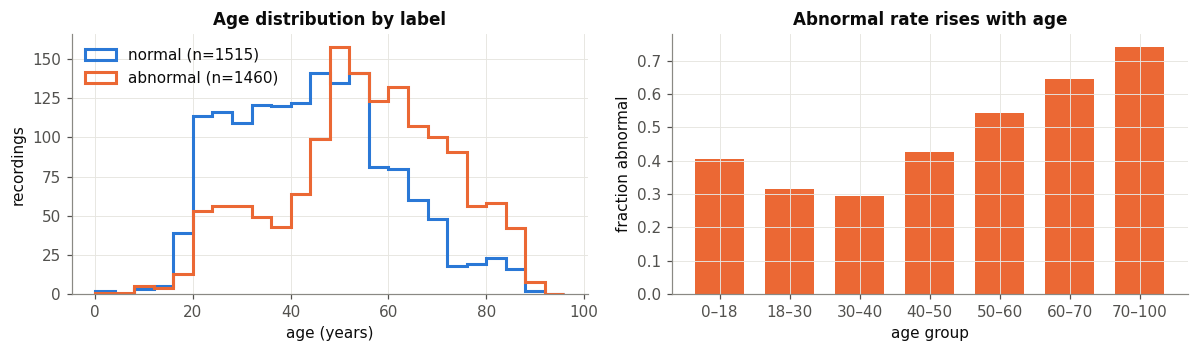

AUROC of age alone for abnormal vs normal: 0.676


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
bins = np.arange(0, 100, 4)
for lab, c in [("normal", C_NORMAL), ("abnormal", C_ABN)]:
    a = age[(meta.label == lab).to_numpy() & age_ok]
    axes[0].hist(a, bins=bins, histtype="step", lw=2, color=c, label=f"{lab} (n={len(a)})")
axes[0].set(xlabel="age (years)", ylabel="recordings", title="Age distribution by label")
axes[0].legend()
dec = pd.cut(meta.age, [0, 18, 30, 40, 50, 60, 70, 100], right=False)
frac = meta.groupby(dec, observed=True).abnormal.mean()
axes[1].bar(range(len(frac)), frac.values, color=C_ABN, width=0.7)
axes[1].set_xticks(range(len(frac)), [f"{int(i.left)}–{int(i.right)}" for i in frac.index])
axes[1].set(xlabel="age group", ylabel="fraction abnormal", title="Abnormal rate rises with age")
plt.tight_layout(); plt.show()

auc_age = stats.mannwhitneyu(age[age_ok & ~normal], age[age_ok & normal]).statistic / (
    (age_ok & ~normal).sum() * (age_ok & normal).sum())
print(f"AUROC of age alone for abnormal vs normal: {auc_age:.3f}")

**Note:** the age distributions differ by label. Abnormal recordings are older, and age
alone separates the classes somewhat. Every pathology model should beat an **age-only
baseline** (§5), and the brain-age gap analysis (§7) needs bias correction.

## 3. Data-preparation audit

### 3.1 What is left in the spectrum after the stored pipeline
`make_TUAB.py` applies a **50 Hz** notch, the European mains frequency. TUH was recorded
in the US, where mains is **60 Hz**, and the 75 Hz low-pass leaves 60 Hz in the signal.
The grand-average PSD (channel-averaged, per recording) shows what actually remains:

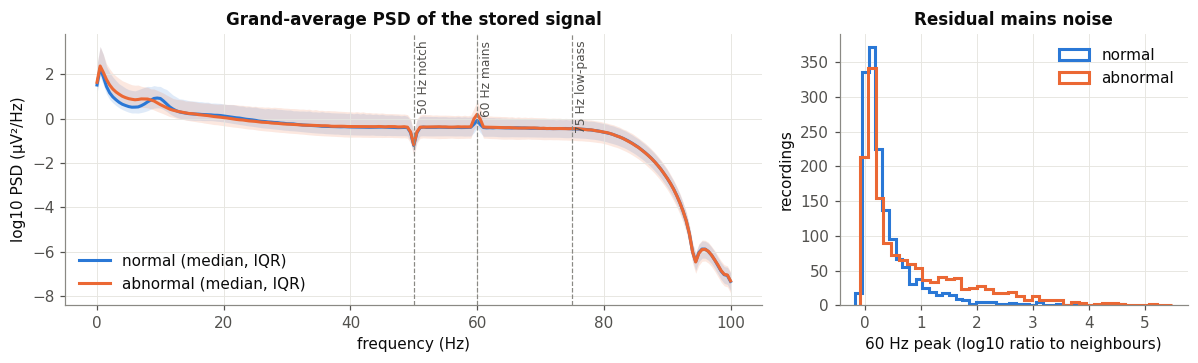

recordings with a 60 Hz peak > 10x neighbours: 19.6%
AUROC of the 60 Hz line-noise level for abnormal vs normal: 0.610
Spearman rho of the 60 Hz level with age: 0.075


In [4]:
freqs_full = D["mean_psd_freqs"][0]
lp = D["mean_psd"]  # [N, 201] log10 µV²/Hz, stored 23-ch signal
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [2, 1]})
for lab, c in [("normal", C_NORMAL), ("abnormal", C_ABN)]:
    m = (meta.label == lab).to_numpy()
    q = np.percentile(lp[m], [25, 50, 75], axis=0)
    axes[0].fill_between(freqs_full, q[0], q[2], color=c, alpha=0.15, lw=0)
    axes[0].plot(freqs_full, q[1], color=c, label=f"{lab} (median, IQR)")
for f0, txt in [(50, "50 Hz notch"), (60, "60 Hz mains"), (75, "75 Hz low-pass")]:
    axes[0].axvline(f0, color="#8a8984", lw=0.8, ls="--")
    axes[0].text(f0 + 0.5, axes[0].get_ylim()[1] - 0.3, txt, fontsize=8, color="#52514e", rotation=90, va="top")
axes[0].set(xlabel="frequency (Hz)", ylabel="log10 PSD (µV²/Hz)", title="Grand-average PSD of the stored signal")
axes[0].legend(loc="lower left")

def line_index(f0):
    on = (freqs_full >= f0 - 0.5) & (freqs_full <= f0 + 0.5)
    off = ((freqs_full >= f0 - 4) & (freqs_full <= f0 - 2)) | ((freqs_full >= f0 + 2) & (freqs_full <= f0 + 4))
    return lp[:, on].max(axis=1) - lp[:, off].mean(axis=1)

line60 = line_index(60.0)
meta["line60_log_ratio"] = line60
for lab, c in [("normal", C_NORMAL), ("abnormal", C_ABN)]:
    axes[1].hist(line60[(meta.label == lab).to_numpy()], bins=40, histtype="step", lw=2, color=c, label=lab)
axes[1].set(xlabel="60 Hz peak (log10 ratio to neighbours)", ylabel="recordings", title="Residual mains noise")
axes[1].legend(); plt.tight_layout(); plt.show()

from sklearn.metrics import roc_auc_score
print(f"recordings with a 60 Hz peak > 10x neighbours: {(line60 > 1).mean():.1%}")
print(f"AUROC of the 60 Hz line-noise level for abnormal vs normal: {roc_auc_score(meta.abnormal, line60):.3f}")
print(f"Spearman rho of the 60 Hz level with age: {stats.spearmanr(line60[age_ok], age[age_ok])[0]:.3f}")

**Takeaways.** The 50 Hz notch removes nothing useful (there is no 50 Hz in TUH). The 60 Hz
mains line is still present in most recordings, and its level differs between groups, so it
is a recording-condition **confound**. Any feature that integrates power above 45 Hz picks it
up: total variance, line length, zero crossings, the DWT detail **D1 (50–100 Hz)** and
**D2 (25–50 Hz)**, and the high WPD nodes. The fix is a **low-pass ≤ 45–49 Hz** (or a 60 Hz
notch) before computing features. The reference preparation does this (1–45 Hz); §3.4
measures what it changes.

### 3.2 Artifacts over time: is skipping the first minute justified?
Window quality is measured on the stored signal. A window is rejected if any sample
exceeds ±800 µV (Gemein 2020's clipping threshold) or a channel is flat (< 0.5 µV std).

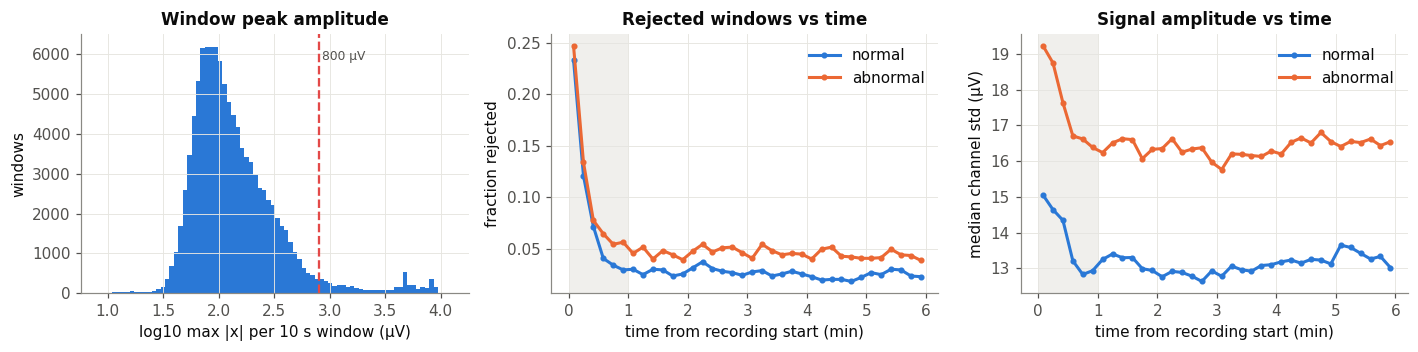

rejected windows: first minute 9.7%, minutes 1-6 3.6%; recordings with no clean window after the skip: 22


In [5]:
q = D["quality"]  # [N, 36, 4]: max|x|, max ptp, min ch std, median ch std
clean = (q[..., 0] <= tuab.REJECT_ABS_UV) & (q[..., 2] >= tuab.FLAT_STD_UV)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
axes[0].hist(np.log10(q[..., 0].ravel()), bins=80, color=PAL[0])
axes[0].axvline(np.log10(800), color=PAL[7], lw=1.5, ls="--")
axes[0].text(np.log10(800) + 0.03, axes[0].get_ylim()[1] * 0.9, "800 µV", color="#52514e", fontsize=8)
axes[0].set(xlabel="log10 max |x| per 10 s window (µV)", ylabel="windows", title="Window peak amplitude")
t_min = (np.arange(36) + 0.5) * 10 / 60
for lab, c in [("normal", C_NORMAL), ("abnormal", C_ABN)]:
    m = (meta.label == lab).to_numpy()
    axes[1].plot(t_min, 1 - clean[m].mean(axis=0), color=c, label=lab, marker="o", ms=3)
    axes[2].plot(t_min, np.median(q[m][..., 3], axis=0), color=c, label=lab, marker="o", ms=3)
for ax in axes[1:]:
    ax.axvspan(0, 1, color="#e6e5e0", alpha=0.6, lw=0); ax.legend()
axes[1].set(xlabel="time from recording start (min)", ylabel="fraction rejected", title="Rejected windows vs time")
axes[2].set(xlabel="time from recording start (min)", ylabel="median channel std (µV)", title="Signal amplitude vs time")
plt.tight_layout(); plt.show()
print(f"rejected windows: first minute {1 - clean[:, :6].mean():.1%}, minutes 1-6 {1 - clean[:, 6:].mean():.1%}; "
      f"recordings with no clean window after the skip: {(~clean[:, 6:].any(axis=1)).sum()}")

### 3.3 Channels and reference
TUAB's `01_tcp_ar` EDFs are average-referenced at acquisition and contain 23 channels, including
the ear electrodes **A1/A2** and the non-10-20 anterior-temporal **T1/T2**. Per-channel
amplitude (median log-variance over clean windows):

/tmp/ipykernel_1006215/626876927.py:2: RuntimeWarning: All-NaN slice encountered
  st_med = np.nanmedian(np.where(clean[..., None], st, np.nan)[:, 6:], axis=1)


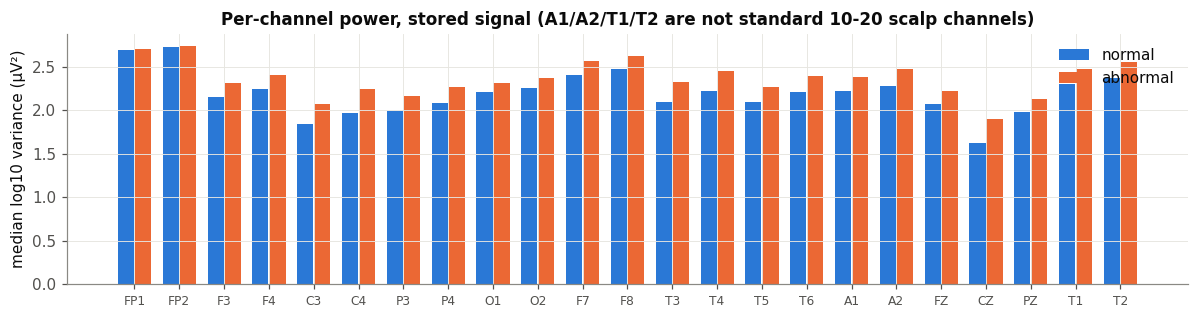

In [6]:
st = D["core/stored_23ch/time"][..., 0]  # log10 variance, [N, 36, 23]
st_med = np.nanmedian(np.where(clean[..., None], st, np.nan)[:, 6:], axis=1)
fig, ax = plt.subplots(figsize=(11, 3))
xs = np.arange(len(tuab.STORED_CHANNELS))
for k, (lab, c) in enumerate([("normal", C_NORMAL), ("abnormal", C_ABN)]):
    m = (meta.label == lab).to_numpy()
    ax.bar(xs + (k - 0.5) * 0.38, np.nanmedian(st_med[m], axis=0), width=0.36, color=c, label=lab)
ax.set_xticks(xs, tuab.STORED_CHANNELS, rotation=0, fontsize=8)
ax.set(ylabel="median log10 variance (µV²)", title="Per-channel power, stored signal (A1/A2/T1/T2 are not standard 10-20 scalp channels)")
ax.legend(); plt.tight_layout(); plt.show()

### 3.4 Preparation ablation
The **core** features (time + spectral + DWT-db4, per channel) are evaluated with the same
linear models and the same subject-grouped 5-fold CV as §5, adding one preparation step at a
time:

| step | channels / reference | filter | windows | rejection | aggregation |
|---|---|---|---|---|---|
| P0 | 23 stored | stored 0.1–75 Hz | 0–35 (incl. first min) | – | mean |
| P1 | 23 stored | stored | **6–35 (skip 1st min)** | – | mean |
| P2 | 23 stored | stored | 6–35 | **±800 µV / flat** | mean |
| P3 | 23 stored | stored | 6–35 | yes | **median** |
| P4 | **19 ch 10-20, CAR** | stored | 6–35 | yes | median |
| P5 | 19 ch, CAR | **1–45 Hz** | 6–35 | yes | median ← *reference* |

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegressionCV, RidgeCV
from sklearn.metrics import (balanced_accuracy_score, mean_absolute_error, r2_score, roc_auc_score)
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SUBJ = meta.subject.to_numpy()
Y = {"abn": meta.abnormal.to_numpy().astype(float), "age": age}
DEV = {"abn": np.where(pool)[0], "age": np.where(pool & normal & age_ok)[0]}
TEST = {"abn": np.where(test)[0], "age": np.where(test & normal & age_ok)[0]}
FOLDS = {
    "abn": list(StratifiedGroupKFold(5, shuffle=True, random_state=0).split(
        DEV["abn"], Y["abn"][DEV["abn"]], SUBJ[DEV["abn"]])),
    "age": list(GroupKFold(5, shuffle=True, random_state=0).split(DEV["age"], groups=SUBJ[DEV["age"]])),
}
print({t: (len(DEV[t]), len(TEST[t])) for t in DEV}, "(development pool, held-out test)")


def make_model(task, kind="linear"):
    if kind == "linear":
        if task == "abn":
            return make_pipeline(StandardScaler(), LogisticRegressionCV(
                Cs=np.logspace(-4, 0, 9), cv=3, scoring="roc_auc", max_iter=5000, n_jobs=N_JOBS))
        return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 5, 25)))
    params = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20,
                  l2_regularization=1.0, early_stopping=False, random_state=0)
    if task == "abn":
        return HistGradientBoostingClassifier(**params)
    return HistGradientBoostingRegressor(loss="absolute_error", **params)


def _predict(model, X, task):
    return model.predict_proba(X)[:, 1] if task == "abn" else model.predict(X)


def scores(task, y, p):
    if task == "abn":
        return {"AUROC": roc_auc_score(y, p), "BAcc": balanced_accuracy_score(y, p >= 0.5)}
    return {"MAE": mean_absolute_error(y, p), "R2": r2_score(y, p), "r": stats.pearsonr(y, p)[0]}


def evaluate(X, task, kind="linear", pre=None, run_test=True):
    # Subject-grouped 5-fold CV on the development pool (+ fit on the whole pool -> held-out test).
    # `pre` is an optional unsupervised transformer fitted inside each fold (e.g. tangent space).
    X = np.asarray(X, dtype=np.float64)
    idx, y = DEV[task], Y[task]

    def pipe():
        m = make_model(task, kind)
        return make_pipeline(clone(pre), m) if pre is not None else m

    oof, per_fold = np.full(len(idx), np.nan), []
    with threadpool_limits(N_JOBS):
        for tr, va in FOLDS[task]:
            m = pipe().fit(X[idx[tr]], y[idx[tr]])
            oof[va] = _predict(m, X[idx[va]], task)
            per_fold.append(scores(task, y[idx[va]], oof[va]))
        out = {}
        for k in per_fold[0]:
            v = [s[k] for s in per_fold]
            out[f"cv_{k}"], out[f"cv_{k}_sd"] = np.mean(v), np.std(v)
        test_pred = None
        if run_test:
            m = pipe().fit(X[idx], y[idx])
            test_pred = _predict(m, X[TEST[task]], task)
            out.update({f"test_{k}": v for k, v in scores(task, y[TEST[task]], test_pred).items()})
    return out, oof, test_pred


def nan_to_median(X):
    # Replace non-finite entries (e.g. log of an exactly-zero band) with the column median.
    X = np.array(X, dtype=np.float64)
    bad = ~np.isfinite(X)
    if bad.any():
        med = np.nanmedian(np.where(bad, np.nan, X), axis=0)
        X[bad] = np.take(med, np.where(bad)[1])
    return X

{'abn': (2714, 276), 'age': (1366, 149)} (development pool, held-out test)


In [8]:
CORE_FAMS = ("time", "spectral", "dwt_db4")


def core_matrix(variant, fams=CORE_FAMS, start=6, reject=True, agg="median", n_windows=None):
    # Per-window core features -> one row per recording.
    sel = np.zeros(36, bool); sel[start:] = True
    mask = sel[None] & (clean if reject else True)
    mask = np.where(mask.any(axis=1, keepdims=True), mask, sel[None])  # fallback: all selected
    if n_windows is not None:
        mask &= np.cumsum(mask, axis=1) <= n_windows
    arr = np.concatenate([D[f"core/{variant}/{f}"] for f in fams], axis=-1)  # [N, 36, C, F]
    arr = np.where(mask[:, :, None, None], arr, np.nan)
    red = np.nanmedian(arr, axis=1) if agg == "median" else np.nanmean(arr, axis=1)
    return nan_to_median(red.reshape(N, -1))


LADDER = [
    ("P0 stored, all windows, mean", dict(variant="stored_23ch", start=0, reject=False, agg="mean")),
    ("P1 + skip 1st minute", dict(variant="stored_23ch", start=6, reject=False, agg="mean")),
    ("P2 + reject artifacts", dict(variant="stored_23ch", start=6, reject=True, agg="mean")),
    ("P3 + median aggregation", dict(variant="stored_23ch", start=6, reject=True, agg="median")),
    ("P4 + 19ch CAR", dict(variant="1020_car", start=6, reject=True, agg="median")),
    ("P5 + 1-45 Hz band-pass", dict(variant="1020_car_1-45Hz", start=6, reject=True, agg="median")),
]
rows = []
t0 = time.time()
for name, kw in LADDER:
    for fams in [CORE_FAMS, ("time",), ("spectral",), ("dwt_db4",)]:
        X = core_matrix(fams=fams, **kw)
        for task in ("abn", "age"):
            r, _, _ = evaluate(X, task, run_test=False)
            rows.append({"prep": name, "features": "+".join(fams), "task": task, **r})
ladder = pd.DataFrame(rows)
print(f"{time.time() - t0:.0f}s")
show = ladder.pivot_table(index="prep", columns=["task", "features"], values=["cv_AUROC", "cv_MAE"], sort=False)
display(show.dropna(axis=1, how="all").round(3))

344s


cv_AUROC                          \
task                                           abn                           
features                     time+spectral+dwt_db4   time spectral dwt_db4   
prep                                                                         
P0 stored, all windows, mean                 0.895  0.812    0.887   0.887   
P1 + skip 1st minute                         0.895  0.813    0.887   0.887   
P2 + reject artifacts                        0.896  0.820    0.888   0.888   
P3 + median aggregation                      0.893  0.827    0.887   0.887   
P4 + 19ch CAR                                0.914  0.849    0.912   0.913   
P5 + 1-45 Hz band-pass                       0.913  0.894    0.910   0.914   

                                            cv_MAE                           
task                                           age                           
features                     time+spectral+dwt_db4    time spectral dwt_db4  
prep                                                                         
P0 stored, all windows, mean                 9.860  12.105    9.846  10.117  
P1 + skip 1st minute                         9.761  12.052    9.860  10.120  
P2 + reject artifacts                        9.682  11.885    9.820  10.082  
P3 + median aggregation                      9.891  12.037   10.114  10.331  
P4 + 19ch CAR                                9.004  11.722    9.038   9.329  
P5 + 1-45 Hz band-pass                       8.827  11.177    8.971   9.139

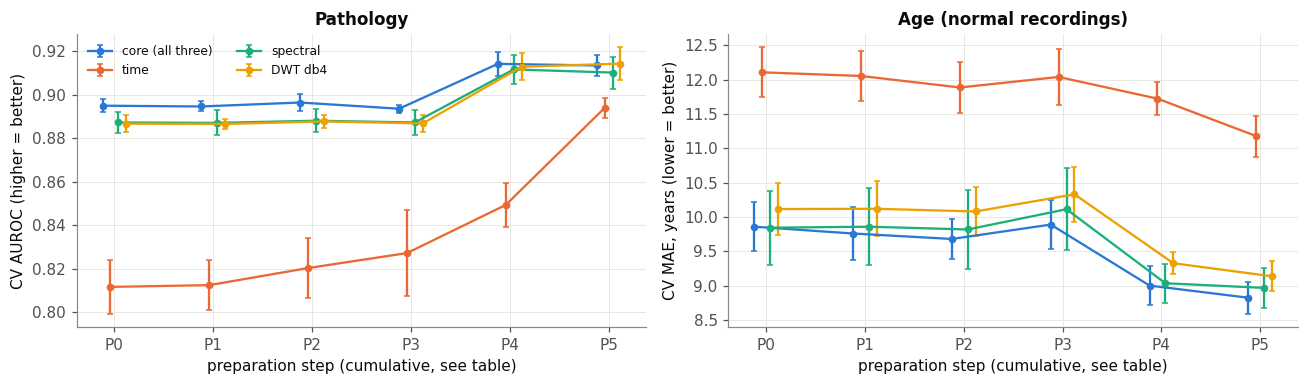

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
fam_order = ["time+spectral+dwt_db4", "time", "spectral", "dwt_db4"]
labels = {"time+spectral+dwt_db4": "core (all three)", "time": "time", "spectral": "spectral", "dwt_db4": "DWT db4"}
for ax, task, metric in [(axes[0], "abn", "cv_AUROC"), (axes[1], "age", "cv_MAE")]:
    for k, fam in enumerate(fam_order):
        d = ladder[(ladder.task == task) & (ladder.features == fam)]
        ax.errorbar(np.arange(len(d)) + (k - 1.5) * 0.08, d[metric], yerr=d[metric + "_sd"],
                    marker="o", ms=4, lw=1.5, capsize=2, color=PAL[k], label=labels[fam])
    ax.set_xticks(range(len(LADDER)), [n.split(" ")[0] for n, _ in LADDER])
    ax.set(xlabel="preparation step (cumulative, see table)",
           ylabel="CV AUROC (higher = better)" if task == "abn" else "CV MAE, years (lower = better)",
           title="Pathology" if task == "abn" else "Age (normal recordings)")
axes[0].legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

### 3.5 How much recording is needed?
Reference preparation, using only the first *n* clean 10 s windows after the skip:

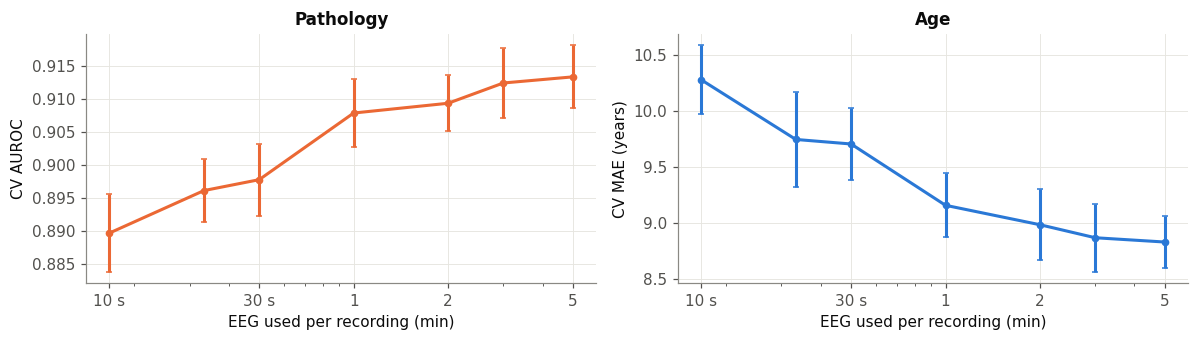

,cv_AUROC,cv_MAE
task,abn,age
windows,,
1,0.890,10.274
2,0.896,9.742
3,0.898,9.702
6,0.908,9.155
12,0.909,8.982
18,0.912,8.866
30,0.913,8.827


In [10]:
rows = []
for n in (1, 2, 3, 6, 12, 18, 30):
    X = core_matrix("1020_car_1-45Hz", n_windows=n)
    for task in ("abn", "age"):
        r, _, _ = evaluate(X, task, run_test=False)
        rows.append({"windows": n, "task": task, **r})
dur = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, task, metric, c in [(axes[0], "abn", "cv_AUROC", C_ABN), (axes[1], "age", "cv_MAE", C_NORMAL)]:
    d = dur[dur.task == task]
    ax.errorbar(d.windows * 10 / 60, d[metric], yerr=d[metric + "_sd"], marker="o", ms=4, capsize=2, color=c)
    ax.set(xscale="log", xlabel="EEG used per recording (min)",
           ylabel="CV AUROC" if task == "abn" else "CV MAE (years)",
           title="Pathology" if task == "abn" else "Age")
    ax.set_xticks([1 / 6, 0.5, 1, 2, 5], ["10 s", "30 s", "1", "2", "5"])
plt.tight_layout(); plt.show()
display(dur.pivot(index="windows", columns="task", values=["cv_AUROC", "cv_MAE"]).dropna(axis=1).round(3))

## 4. Visual analytics: how features relate to pathology and age
All features from here on use the **reference preparation** (P5) and are
recording-level medians.

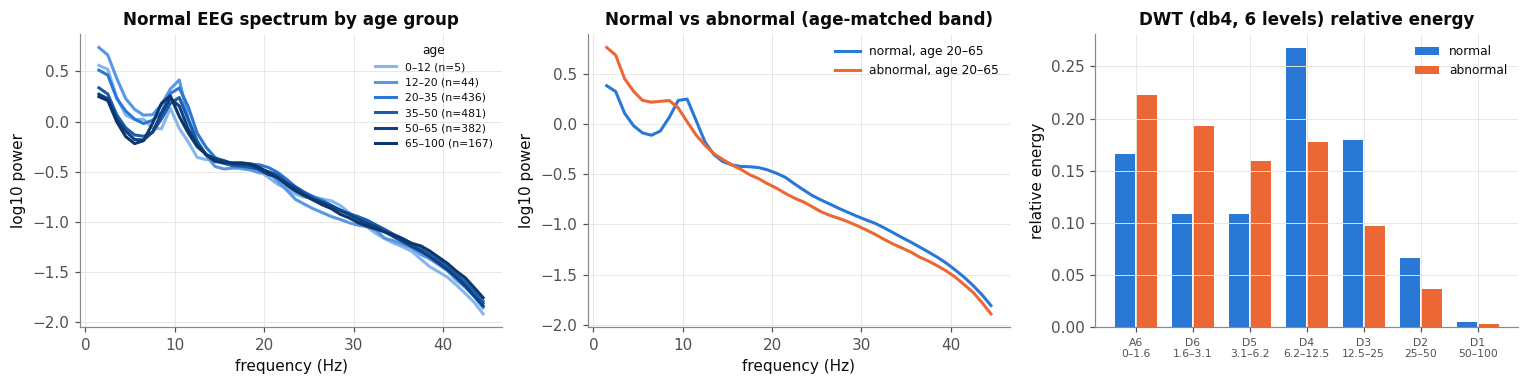

In [11]:
def rec(fam):
    return D[f"rec/{fam}"]  # [N, 19, F]

age_groups = pd.cut(meta.age, [0, 12, 20, 35, 50, 65, 100], right=False)
grp_labels = [f"{int(i.left)}–{int(i.right)}" for i in age_groups.cat.categories]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
f_bins = np.arange(1, 45)
psd = rec("psd_bins").mean(axis=1)  # channel-averaged log PSD, 1 Hz bins
for k, g in enumerate(age_groups.cat.categories):
    m = normal & (age_groups == g).to_numpy()
    if m.sum() < 5:
        continue
    axes[0].plot(f_bins + 0.5, np.median(psd[m], axis=0), color=SEQ[k], label=f"{grp_labels[k]} (n={m.sum()})")
axes[0].set(xlabel="frequency (Hz)", ylabel="log10 power", title="Normal EEG spectrum by age group")
axes[0].legend(fontsize=7, title="age", title_fontsize=8)
for lab, c in [("normal", C_NORMAL), ("abnormal", C_ABN)]:
    m = (meta.label == lab).to_numpy() & (age >= 20) & (age < 65)
    axes[1].plot(f_bins + 0.5, np.median(psd[m], axis=0), color=c, label=f"{lab}, age 20–65")
axes[1].set(xlabel="frequency (Hz)", ylabel="log10 power", title="Normal vs abnormal (age-matched band)")
axes[1].legend(fontsize=8)
# DWT relative energy per level
dn = NAMES["dwt_db4_L6"]
rel_idx = [i for i, n in enumerate(dn) if n.startswith("rel_E_")]
rel = rec("dwt_db4_L6")[..., rel_idx].mean(axis=1)
lev = [dn[i][len("rel_E_"):] for i in rel_idx]
w = 0.38
for k, (lab, c) in enumerate([("normal", C_NORMAL), ("abnormal", C_ABN)]):
    m = (meta.label == lab).to_numpy()
    axes[2].bar(np.arange(len(lev)) + (k - 0.5) * w, np.median(rel[m], axis=0), width=w * 0.95, color=c, label=lab)
axes[2].set_xticks(range(len(lev)), [f"{l}\n{lo:.1f}–{hi:.1f}".replace(".0", "") for l, (lo, hi) in zip(lev, fx.dwt_band_edges(6))], fontsize=7)
axes[2].set(ylabel="relative energy", title="DWT (db4, 6 levels) relative energy")
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

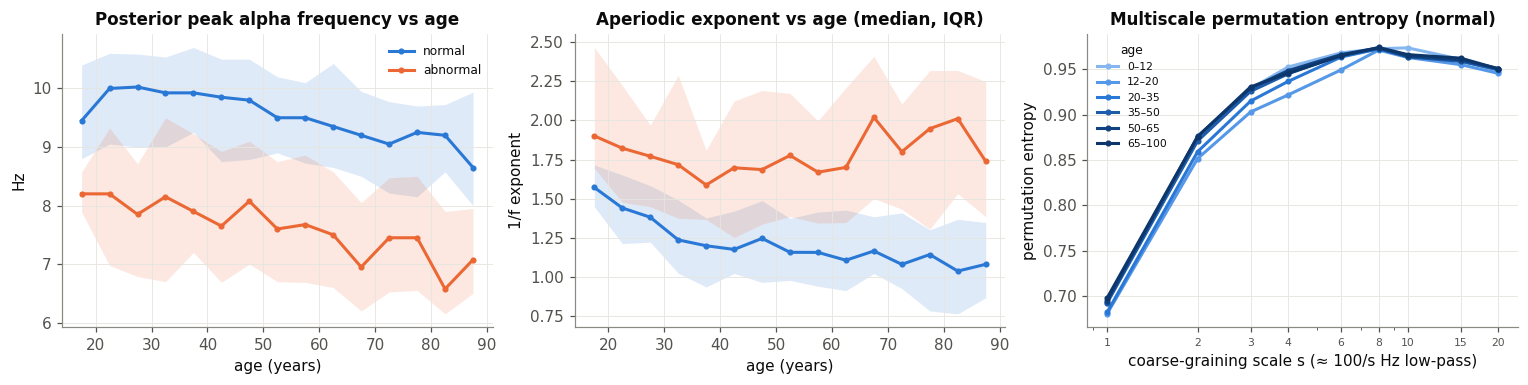

In [12]:
sn = NAMES["spectral"]
paf = rec("spectral")[..., sn.index("peak_alpha_freq")]
chi = rec("spectral")[..., sn.index("aperiodic_exponent")]
post = [CH.index(c) for c in ("O1", "O2", "P3", "P4", "PZ")]
mspe = rec("mspe").mean(axis=1)
scales = [int(n.split("_s")[1]) for n in NAMES["mspe"]]

def binned(ax, x, y, color, label):
    edges = np.arange(0, 95, 5)
    mids, med, lo, hi = [], [], [], []
    for a, b in zip(edges[:-1], edges[1:]):
        s = y[(x >= a) & (x < b)]
        if len(s) >= 10:
            mids.append((a + b) / 2); med.append(np.median(s)); lo.append(np.percentile(s, 25)); hi.append(np.percentile(s, 75))
    ax.fill_between(mids, lo, hi, color=color, alpha=0.15, lw=0)
    ax.plot(mids, med, color=color, marker="o", ms=3, label=label)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for lab, c in [("normal", C_NORMAL), ("abnormal", C_ABN)]:
    m = (meta.label == lab).to_numpy() & age_ok
    binned(axes[0], age[m], paf[m][:, post].mean(axis=1), c, lab)
    binned(axes[1], age[m], chi[m].mean(axis=1), c, lab)
axes[0].set(xlabel="age (years)", ylabel="Hz", title="Posterior peak alpha frequency vs age")
axes[1].set(xlabel="age (years)", ylabel="1/f exponent", title="Aperiodic exponent vs age (median, IQR)")
axes[0].legend(fontsize=8)
for k, g in enumerate(age_groups.cat.categories):
    m = normal & (age_groups == g).to_numpy()
    if m.sum() < 5:
        continue
    axes[2].plot(scales, np.median(mspe[m], axis=0), color=SEQ[k], marker="o", ms=3, label=grp_labels[k])
axes[2].set(xscale="log", xlabel="coarse-graining scale s (≈ 100/s Hz low-pass)", ylabel="permutation entropy",
            title="Multiscale permutation entropy (normal)")
axes[2].set_xticks(scales, scales, fontsize=7); axes[2].legend(fontsize=7, title="age", title_fontsize=8)
plt.tight_layout(); plt.show()

### 4.1 What a multi-scale decomposition looks like
One 30 s excerpt from a normal and an abnormal adult recording (O1, reference preparation):
the Morlet scalogram (cmor1.5-1.0, ≈5.4 cycles) and the DWT-db4 coefficients per level.

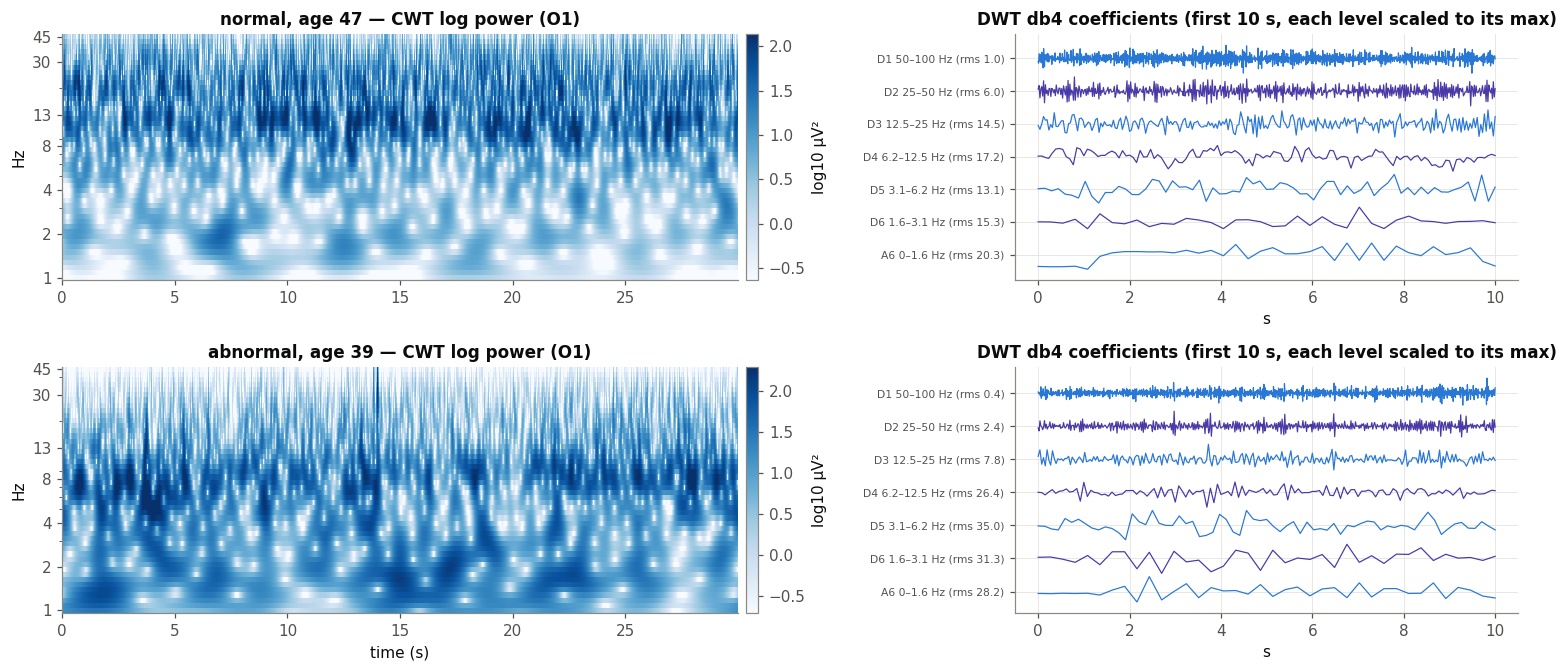

In [13]:
def band_str(lo, hi):
    f = lambda v: f"{v:.1f}".rstrip("0").rstrip(".")
    return f"{f(lo)}–{f(hi)}"


def pick(label, lo=30, hi=50):
    m = (meta.label == label) & meta.age.between(lo, hi) & test
    return meta[m].iloc[0]

fig, axes = plt.subplots(2, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1.6, 1]})
f_cwt = fx.cwt_frequencies(48, 1, 45)
for row, lab in enumerate(["normal", "abnormal"]):
    r = pick(lab)
    seg = tuab.load_segment(os.path.join(NPY_ROOT, "recordings", r.stem + ".npy"), 12)
    x = tuab.prepare(seg, tuab.PREP_REF)[CH.index("O1"), 6 * 2000: 9 * 2000]
    logp = fx.cwt_log_power(x[None], f_cwt)[:, 0]
    tt = np.arange(len(x)) / 200
    ax = axes[row, 0]
    pcm = ax.pcolormesh(tt, f_cwt, logp, shading="auto", cmap="Blues", vmin=np.percentile(logp, 5), vmax=np.percentile(logp, 99.5))
    ax.set(yscale="log", ylabel="Hz", title=f"{lab}, age {r.age:.0f} — CWT log power (O1)")
    ax.set_yticks([1, 2, 4, 8, 13, 30, 45], [1, 2, 4, 8, 13, 30, 45]); ax.grid(False)
    plt.colorbar(pcm, ax=ax, label="log10 µV²", pad=0.01)
    coeffs = pywt.wavedec(x[:2000], "db4", level=6)
    ax = axes[row, 1]
    labels_l = ["A6"] + [f"D{j}" for j in range(6, 0, -1)]
    for k, c in enumerate(coeffs):
        tc = np.linspace(0, 10, len(c))
        cc = c - c.mean()
        ax.plot(tc, k + 0.45 * cc / np.abs(cc).max(), lw=0.8, color=PAL[0] if k % 2 == 0 else PAL[6])
    rms = [np.sqrt((c ** 2).mean()) for c in coeffs]
    ax.set_yticks(range(7), [f"{l} {band_str(lo, hi)} Hz (rms {r:.1f})" for l, (lo, hi), r in zip(labels_l, fx.dwt_band_edges(6), rms)], fontsize=7)
    ax.set(xlabel="s", title="DWT db4 coefficients (first 10 s, each level scaled to its max)")
axes[1, 0].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

### 4.2 Univariate screening
Each (feature, channel) pair is scored on the development pool: Spearman ρ with age on normal
recordings, and AUROC for abnormal vs normal on all recordings. Below are the strongest
single features of each family, then a channel × feature map for the spectral family.

In [14]:
FAMS_SCREEN = ["time", "spectral", "dwt_db4_L6", "wpd_db4_L5", "cwt_cmor1.5-1.0", "scat_J7_Q8", "mspe"]
rows = []
ia, ix = DEV["age"], DEV["abn"]
for fam in FAMS_SCREEN:
    arr = rec(fam)
    for j, fn in enumerate(NAMES[fam]):
        for c, ch in enumerate(CH):
            v = arr[:, c, j]
            ok_a, ok_x = np.isfinite(v[ia]), np.isfinite(v[ix])
            rho = stats.spearmanr(v[ia][ok_a], age[ia][ok_a])[0]
            auc = roc_auc_score(Y["abn"][ix][ok_x], v[ix][ok_x])
            rows.append({"family": fam, "feature": fn, "channel": ch, "rho_age": rho, "auroc_abn": auc})
uni = pd.DataFrame(rows)
uni["auc_dist"] = (uni.auroc_abn - 0.5).abs()
best = uni.loc[uni.groupby("family").rho_age.apply(lambda s: s.abs().idxmax())][["family", "feature", "channel", "rho_age"]]
best2 = uni.loc[uni.groupby("family").auc_dist.idxmax()][["family", "feature", "channel", "auroc_abn"]]
display(best.merge(best2, on="family", suffixes=("_age", "_abn")).round(3))
print("Top 12 single features for age:")
display(uni.reindex(uni.rho_age.abs().sort_values(ascending=False).index).head(12)[["family", "feature", "channel", "rho_age", "auroc_abn"]].round(3))
print("Top 12 single features for pathology:")
display(uni.sort_values("auc_dist", ascending=False).head(12)[["family", "feature", "channel", "auroc_abn", "rho_age"]].round(3))

,family,feature_age,channel_age,rho_age,feature_abn,channel_abn,auroc_abn
0,cwt_cmor1.5-1.0,cwt_mean_2.2Hz,FZ,-0.421,cwt_mean_1.6Hz,T3,0.794
1,dwt_db4_L6,log_E_D6,FZ,-0.390,rel_E_D3,O2,0.173
2,mspe,mspe_s1,F3,0.215,mspe_s6,T3,0.198
3,scat_J7_Q8,S1_3.85Hz,CZ,-0.408,S1_1.62Hz,T3,0.790
4,spectral,log_abs_delta,CZ,-0.391,log_theta_alpha,T6,0.849
5,time,zero_cross_rate,F4,0.258,hjorth_complexity,O2,0.815
6,wpd_db4_L5,log_E_wp_0-3.125Hz,CZ,-0.363,log_E_wp_0-3.125Hz,T3,0.788


Top 12 single features for age:


,family,feature,channel,rho_age,auroc_abn
1156,cwt_cmor1.5-1.0,cwt_mean_2.2Hz,FZ,-0.421,0.733
1175,cwt_cmor1.5-1.0,cwt_mean_2.6Hz,FZ,-0.419,0.729
1233,cwt_cmor1.5-1.0,cwt_mean_4.2Hz,CZ,-0.415,0.694
1137,cwt_cmor1.5-1.0,cwt_mean_1.9Hz,FZ,-0.414,0.735
1252,cwt_cmor1.5-1.0,cwt_mean_4.9Hz,CZ,-0.411,0.681
1194,cwt_cmor1.5-1.0,cwt_mean_3.0Hz,FZ,-0.410,0.729
2544,scat_J7_Q8,S1_3.85Hz,CZ,-0.408,0.700
1118,cwt_cmor1.5-1.0,cwt_mean_1.6Hz,FZ,-0.408,0.741
1176,cwt_cmor1.5-1.0,cwt_mean_2.6Hz,CZ,-0.407,0.708
1195,cwt_cmor1.5-1.0,cwt_mean_3.0Hz,CZ,-0.406,0.704


Top 12 single features for pathology:


,family,feature,channel,auroc_abn,rho_age
338,spectral,log_theta_alpha,T6,0.849,-0.030
357,spectral,log_slowing_ratio,T6,0.840,-0.102
332,spectral,log_theta_alpha,O2,0.838,0.041
351,spectral,log_slowing_ratio,O2,0.837,-0.009
337,spectral,log_theta_alpha,T5,0.833,-0.025
330,spectral,log_theta_alpha,P4,0.831,-0.058
356,spectral,log_slowing_ratio,T5,0.830,-0.106
331,spectral,log_theta_alpha,O1,0.829,0.031
350,spectral,log_slowing_ratio,O1,0.828,-0.036
325,spectral,log_theta_alpha,F3,0.827,-0.088


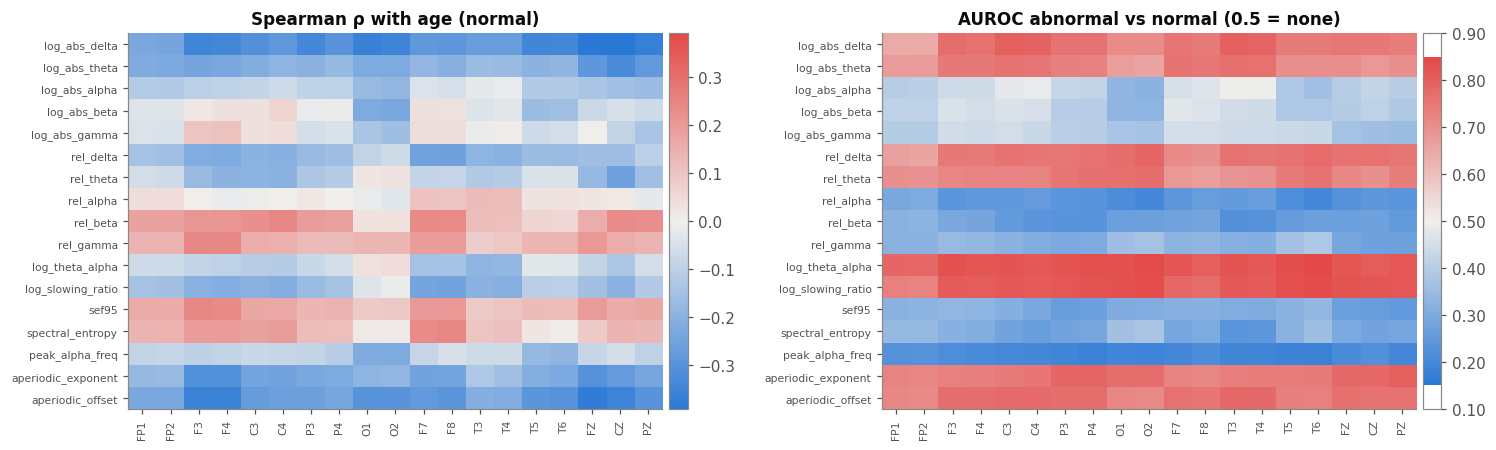

In [15]:
from matplotlib.colors import LinearSegmentedColormap
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
s = uni[uni.family == "spectral"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, col, title, lim in [(axes[0], "rho_age", "Spearman ρ with age (normal)", 0.6),
                            (axes[1], "auroc_abn", "AUROC abnormal vs normal (0.5 = none)", None)]:
    mat = s.pivot(index="feature", columns="channel", values=col).loc[NAMES["spectral"], CH]
    vals = mat.to_numpy() - (0.5 if col == "auroc_abn" else 0)
    lim = np.nanmax(np.abs(vals))
    im = ax.imshow(vals, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(len(CH)), CH, fontsize=7, rotation=90); ax.set_yticks(range(len(mat)), mat.index, fontsize=7)
    ax.grid(False); ax.set_title(title)
    cb = plt.colorbar(im, ax=ax, pad=0.01)
    if col == "auroc_abn":
        cb.set_ticks(cb.get_ticks()); cb.set_ticklabels([f"{t + 0.5:.2f}" for t in cb.get_ticks()])
plt.tight_layout(); plt.show()

## 5. Benchmark: one model per feature family
Protocol:
* **Development pool** = TUAB `train` (both labels). Subject-grouped, stratified **5-fold CV** gives mean ± SD across folds.
* **Held-out test** = the official TUAB `eval` set. The model is refit on the whole pool once and scored on test.
* **Age** models are trained and tested on **normal** recordings only.
* **Models:** standardised **linear** models (L2 logistic regression with the C chosen by inner CV; RidgeCV) and **gradient-boosted trees** (`HistGradientBoosting`, fixed hyper-parameters; absolute-error loss for age).
* **Filterbank-Riemann:** six band covariances (1–4, 4–8, 8–13, 13–20, 20–30, 30–45 Hz), projected onto the 18-dim CAR subspace (CAR makes the 19×19 covariance rank 18), then mapped to the **tangent space at the training-fold Riemannian mean**.

In [16]:
from scipy.linalg import null_space
from labram.features.riemann import mean_riemann, tangent_space

U_CAR = null_space(np.ones((1, len(CH))))  # 19 x 18 orthonormal basis orthogonal to the CAR null vector
NB = len(fx.FILTERBANK)


class FBTangentSpace(BaseEstimator, TransformerMixin):
    # Filter-bank covariances (flattened in the last n_bands*19*19 columns) -> tangent vectors.
    # The leading `n_passthrough` columns are passed through unchanged (for combined models).
    def __init__(self, n_passthrough=0, shrink=1e-3):
        self.n_passthrough, self.shrink = n_passthrough, shrink

    def _covs(self, X):
        C = X[:, self.n_passthrough:].reshape(len(X), NB, len(CH), len(CH))
        C = U_CAR.T @ C @ U_CAR  # project onto the 18-dim CAR subspace
        tr = np.trace(C, axis1=-2, axis2=-1)[..., None, None] / C.shape[-1]
        return (1 - self.shrink) * C + self.shrink * tr * np.eye(C.shape[-1])

    def fit(self, X, y=None):
        C = self._covs(X)
        self.refs_ = [mean_riemann(C[:, b]) for b in range(NB)]
        return self

    def transform(self, X):
        C = self._covs(X)
        ts = [tangent_space(C[:, b], self.refs_[b]) for b in range(NB)]
        return np.concatenate([X[:, : self.n_passthrough]] + ts, axis=1)


X_FB = D["fbcov"].reshape(N, -1).astype(np.float64)


def Xrec(*fams):
    return nan_to_median(np.concatenate([rec(f).reshape(N, -1) for f in fams], axis=1))


FAMILIES = {
    "Time (Hjorth, line length, moments)": ("time",),
    "Spectral (bands, ratios, PAF, 1/f)": ("spectral",),
    "Log-PSD, 1 Hz bins": ("psd_bins",),
    "DWT db4, 6 levels": ("dwt_db4_L6",),
    "WPD db4, 3.125 Hz nodes": ("wpd_db4_L5",),
    "CWT Morlet (mean+std over time)": ("cwt_cmor1.5-1.0",),
    "Wavelet scattering (orders 1+2)": ("scat_J7_Q8",),
    "Multiscale permutation entropy": ("mspe",),
    "Filterbank Riemann (tangent space)": "riemann",
}
ALL_FLAT = ("time", "spectral", "psd_bins", "dwt_db4_L6", "wpd_db4_L5", "cwt_cmor1.5-1.0", "scat_J7_Q8", "mspe")

In [17]:
def n_features(X, pre):
    # Tangent space of an 18x18 SPD matrix has 18*19/2 = 171 coordinates per band.
    if pre is None:
        return X.shape[1]
    return pre.n_passthrough + NB * 171


bench, PRED = [], {}
t0 = time.time()
for name, fams in list(FAMILIES.items()) + [("All families combined", "all")]:
    if fams == "riemann":
        X, pre = X_FB, FBTangentSpace()
    elif fams == "all":
        Xf = Xrec(*ALL_FLAT)
        X, pre = np.concatenate([Xf, X_FB], axis=1), FBTangentSpace(n_passthrough=Xf.shape[1])
    else:
        X, pre = Xrec(*fams), None
    for kind in ("linear", "hgb"):
        for task in ("abn", "age"):
            r, oof, tp = evaluate(X, task, kind, pre=pre)
            PRED[(name, kind, task)] = (oof, tp)
            bench.append({"family": name, "model": kind, "task": task, "n_features": n_features(X, pre), **r})
    print(f"{name:42s} done ({time.time() - t0:.0f}s)")

# baselines
demo = np.c_[np.nan_to_num(age, nan=np.nanmedian(age)), (meta.sex == "F").astype(float)]
for kind in ("linear", "hgb"):
    r, _, _ = evaluate(demo, "abn", kind)
    bench.append({"family": "Baseline: age + sex only", "model": kind, "task": "abn", "n_features": 2, **r})
dummy_cv = [mean_absolute_error(Y["age"][DEV["age"]][va], np.full(len(va), np.median(Y["age"][DEV["age"]][tr]))) for tr, va in FOLDS["age"]]
bench.append({"family": "Baseline: predict median age", "model": "dummy", "task": "age", "n_features": 0,
              "cv_MAE": np.mean(dummy_cv), "cv_MAE_sd": np.std(dummy_cv),
              "test_MAE": mean_absolute_error(Y["age"][TEST["age"]], np.full(len(TEST["age"]), np.median(Y["age"][DEV["age"]]))),
              "test_R2": 0.0})
bench = pd.DataFrame(bench)

Time (Hjorth, line length, moments)        done (16s)


Spectral (bands, ratios, PAF, 1/f)         done (45s)


Log-PSD, 1 Hz bins                         done (115s)


DWT db4, 6 levels                          done (144s)


WPD db4, 3.125 Hz nodes                    done (174s)


CWT Morlet (mean+std over time)            done (261s)


Wavelet scattering (orders 1+2)            done (597s)


Multiscale permutation entropy             done (646s)


Filterbank Riemann (tangent space)         done (881s)


All families combined                      done (1911s)


In [18]:
cols_abn = ["family", "model", "n_features", "cv_AUROC", "cv_AUROC_sd", "cv_BAcc", "test_AUROC", "test_BAcc"]
cols_age = ["family", "model", "n_features", "cv_MAE", "cv_MAE_sd", "cv_R2", "test_MAE", "test_R2", "test_r"]
print("Pathology (abnormal vs normal) - sorted by CV AUROC")
display(bench[bench.task == "abn"][cols_abn].sort_values("cv_AUROC", ascending=False).round(3).reset_index(drop=True))
print("Age (normal recordings) - sorted by CV MAE (years)")
display(bench[bench.task == "age"][cols_age].sort_values("cv_MAE").round(3).reset_index(drop=True))

Pathology (abnormal vs normal) - sorted by CV AUROC


,family,model,n_features,cv_AUROC,cv_AUROC_sd,cv_BAcc,test_AUROC,test_BAcc
0,All families combined,hgb,7353,0.925,0.004,0.852,0.929,0.849
1,Filterbank Riemann (tangent space),linear,1026,0.922,0.007,0.844,0.918,0.831
2,All families combined,linear,7353,0.921,0.004,0.853,0.921,0.818
3,Filterbank Riemann (tangent space),hgb,1026,0.918,0.003,0.842,0.917,0.843
4,"DWT db4, 6 levels",hgb,285,0.917,0.009,0.839,0.921,0.836
5,"DWT db4, 6 levels",linear,285,0.914,0.007,0.835,0.896,0.810
6,CWT Morlet (mean+std over time),hgb,950,0.914,0.006,0.831,0.925,0.829
7,"Spectral (bands, ratios, PAF, 1/f)",hgb,323,0.914,0.007,0.833,0.924,0.814
8,"Spectral (bands, ratios, PAF, 1/f)",linear,323,0.910,0.007,0.830,0.899,0.818
9,"Log-PSD, 1 Hz bins",hgb,836,0.910,0.010,0.833,0.922,0.834


Age (normal recordings) - sorted by CV MAE (years)


,family,model,n_features,cv_MAE,cv_MAE_sd,cv_R2,test_MAE,test_R2,test_r
0,All families combined,linear,7353,8.040,0.408,0.569,7.204,0.656,0.814
1,Filterbank Riemann (tangent space),linear,1026,8.223,0.353,0.560,7.582,0.640,0.804
2,"Log-PSD, 1 Hz bins",linear,836,8.476,0.291,0.533,7.623,0.634,0.798
3,"Spectral (bands, ratios, PAF, 1/f)",linear,323,8.971,0.296,0.483,8.368,0.584,0.766
4,"WPD db4, 3.125 Hz nodes",linear,304,9.054,0.195,0.484,8.439,0.572,0.756
5,CWT Morlet (mean+std over time),linear,950,9.066,0.478,0.465,8.296,0.554,0.747
6,"DWT db4, 6 levels",linear,285,9.139,0.216,0.467,8.470,0.566,0.754
7,Wavelet scattering (orders 1+2),linear,3325,9.277,0.345,0.447,8.490,0.501,0.712
8,All families combined,hgb,7353,9.584,0.239,0.424,9.004,0.512,0.741
9,"Log-PSD, 1 Hz bins",hgb,836,9.642,0.244,0.409,8.953,0.497,0.720


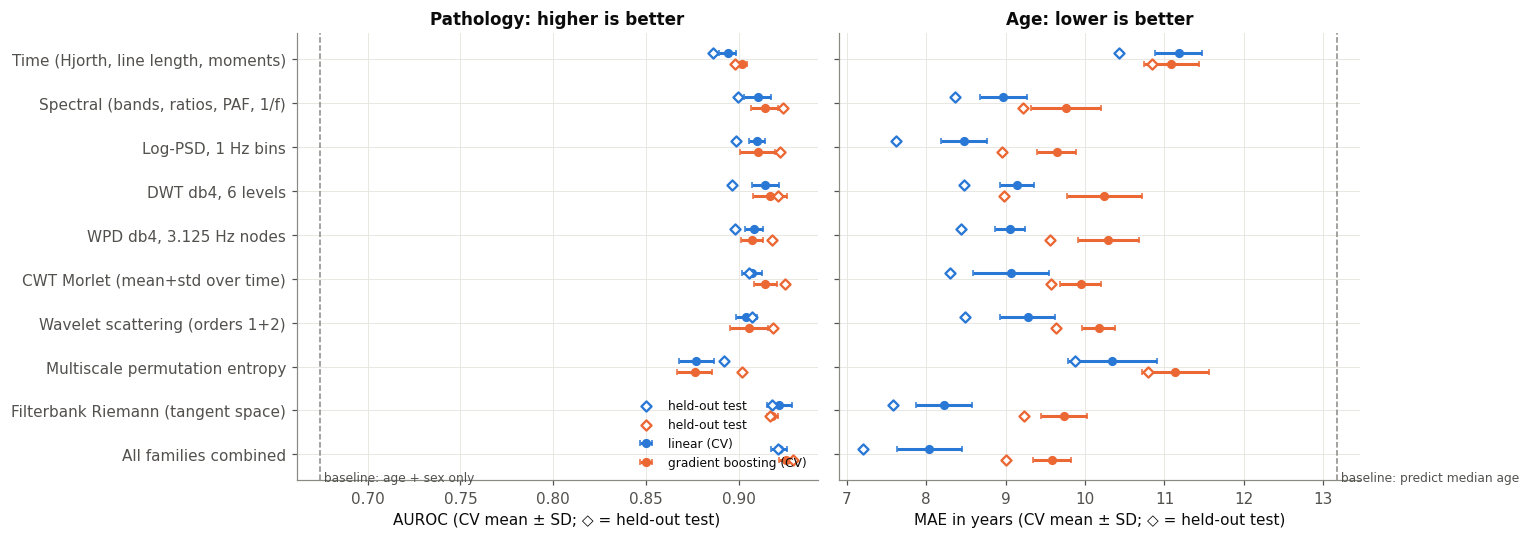

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
order = list(FAMILIES) + ["All families combined"]
yy = np.arange(len(order))
for ax, task, metric, ref in [(axes[0], "abn", "cv_AUROC", None), (axes[1], "age", "cv_MAE", None)]:
    for k, (kind, c) in enumerate([("linear", PAL[0]), ("hgb", PAL[1])]):
        d = bench[(bench.task == task) & (bench.model == kind)].set_index("family").reindex(order)
        ax.errorbar(d[metric], yy + (k - 0.5) * 0.25, xerr=d[metric + "_sd"], fmt="o", ms=5, capsize=2,
                    color=c, label={"linear": "linear (CV)", "hgb": "gradient boosting (CV)"}[kind])
        ax.scatter(d["test_" + metric[3:]], yy + (k - 0.5) * 0.25, marker="D", s=22, facecolor="white",
                   edgecolor=c, linewidth=1.5, zorder=3, label="held-out test")
    base = bench[(bench.task == task) & bench.family.str.startswith("Baseline")]
    bval = base[metric].max() if task == "abn" else base[metric].min()
    ax.axvline(bval, color="#8a8984", ls="--", lw=1)
    ax.text(bval, len(order) - 0.4, " " + base.sort_values(metric).family.iloc[-1 if task == "abn" else 0].replace("Baseline: ", "baseline: "),
            fontsize=8, color="#52514e")
    ax.set_yticks(yy, order)
    ax.set(xlabel="AUROC (CV mean ± SD; ◇ = held-out test)" if task == "abn" else "MAE in years (CV mean ± SD; ◇ = held-out test)",
           title="Pathology: higher is better" if task == "abn" else "Age: lower is better")
axes[0].invert_yaxis(); axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 6. Multi-scale deep dive

### 6.1 Which mother wavelet?
First, what the choice does physically. A sine sweep is pushed through a 6-level DWT and the
fraction of its energy that lands in each level is measured. Ideal filters would give clean
rectangles at the nominal dyadic bands (dashed lines).

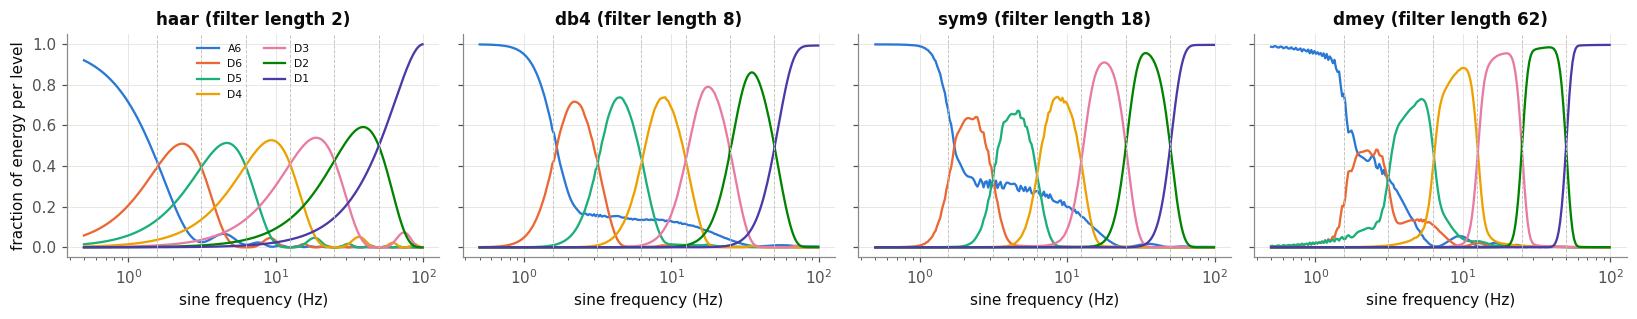

In [20]:
sweep = np.geomspace(0.5, 99, 220)
tt = np.arange(2000) / 200
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, w in zip(axes, ["haar", "db4", "sym9", "dmey"]):
    E = []
    for f in sweep:
        e = np.zeros(7)
        for ph in np.linspace(0, np.pi, 6, endpoint=False):  # average over phases
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                cs = pywt.wavedec(np.sin(2 * np.pi * f * tt + ph), w, level=6)
            ei = np.array([(c ** 2).sum() for c in cs]); e += ei / ei.sum()
        E.append(e / 6)
    E = np.array(E)
    for k in range(7):
        ax.plot(sweep, E[:, k], lw=1.5, color=PAL[k % len(PAL)])
    for lo, hi in fx.dwt_band_edges(6)[1:]:
        ax.axvline(lo, color="#c3c2b7", lw=0.6, ls="--")
    w_obj = pywt.Wavelet(w)
    ax.set(xscale="log", title=f"{w} (filter length {w_obj.dec_len})", xlabel="sine frequency (Hz)")
axes[0].set_ylabel("fraction of energy per level")
axes[0].legend(["A6"] + [f"D{j}" for j in range(6, 0, -1)], fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

Short filters (Haar) leak heavily into neighbouring levels. Long filters (sym9, dmey) are close
to ideal, at the cost of boundary effects (dmey's 62-tap filter is longer than the deepest
level's data on a 10 s window). Does this matter for prediction? Here is the same DWT feature
set (log energy, relative energy, wavelet entropy per level, 19 channels) for each mother
wavelet:

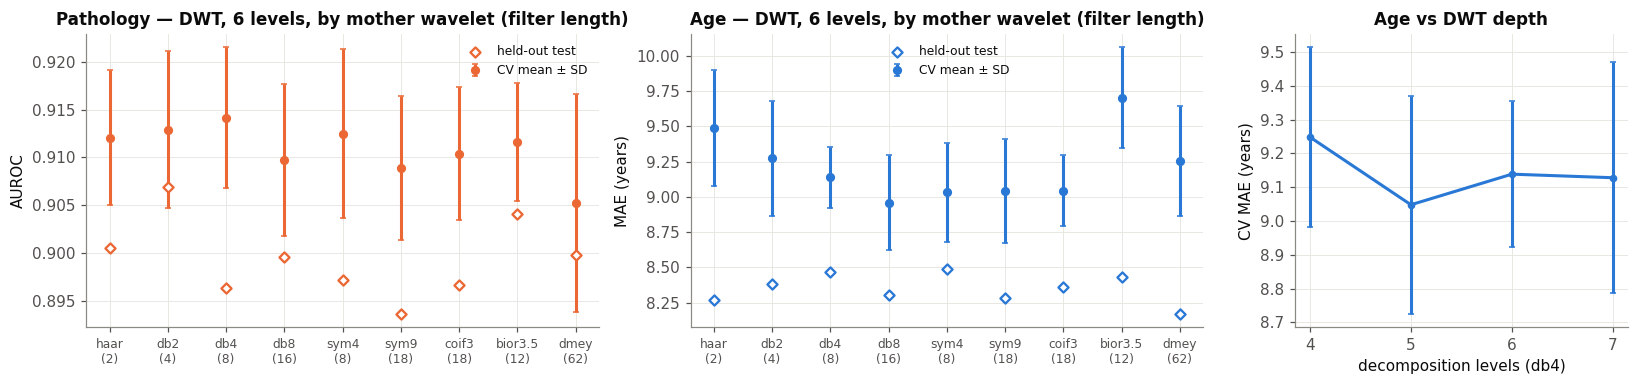

,cv_AUROC,cv_MAE,test_AUROC,test_MAE
task,abn,age,abn,age
wavelet,,,,
haar,0.912,9.490,0.900,8.270
db2,0.913,9.274,0.907,8.384
db4,0.914,9.139,0.896,8.470
db8,0.910,8.960,0.900,8.302
sym4,0.912,9.034,0.897,8.486
sym9,0.909,9.041,0.894,8.286
coif3,0.910,9.043,0.897,8.358
bior3.5,0.912,9.702,0.904,8.430


In [21]:
rows = []
for w in tuab.DWT_WAVELETS:
    X = Xrec(f"dwt_{w}_L6")
    for task in ("abn", "age"):
        r, _, _ = evaluate(X, task)
        rows.append({"wavelet": w, "filter_len": pywt.Wavelet(w).dec_len, "task": task, **r})
wav = pd.DataFrame(rows)
for lev in tuab.DWT_LEVELS:
    X = Xrec(f"dwt_db4_L{lev}")
    for task in ("abn", "age"):
        r, _, _ = evaluate(X, task)
        rows.append({"wavelet": f"db4 L{lev}", "filter_len": 8, "task": task, "level": lev, **r})
wav_all = pd.DataFrame(rows)
lvl = wav_all[wav_all.wavelet.str.startswith("db4 L")]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [2, 2, 1.3]})
for ax, task, metric, c in [(axes[0], "abn", "cv_AUROC", C_ABN), (axes[1], "age", "cv_MAE", C_NORMAL)]:
    d = wav[wav.task == task]
    ax.errorbar(range(len(d)), d[metric], yerr=d[metric + "_sd"], fmt="o", ms=5, capsize=2, color=c, label="CV mean ± SD")
    ax.scatter(range(len(d)), d["test_" + metric[3:]], marker="D", s=22, facecolor="white", edgecolor=c, lw=1.5, zorder=3, label="held-out test")
    ax.set_xticks(range(len(d)), [f"{w}\n({L})" for w, L in zip(d.wavelet, d.filter_len)], fontsize=8)
    ax.set(ylabel="AUROC" if task == "abn" else "MAE (years)", title=("Pathology" if task == "abn" else "Age") + " — DWT, 6 levels, by mother wavelet (filter length)")
    ax.legend(fontsize=8)
d_g = lvl[lvl.task == "age"]
axes[2].errorbar(d_g.level, d_g.cv_MAE, yerr=d_g.cv_MAE_sd, marker="o", ms=4, capsize=2, color=C_NORMAL)
axes[2].set(xlabel="decomposition levels (db4)", ylabel="CV MAE (years)", title="Age vs DWT depth")
axes[2].set_xticks(list(tuab.DWT_LEVELS))
plt.tight_layout(); plt.show()
display(wav_all.pivot_table(index="wavelet", columns="task", values=["cv_AUROC", "cv_MAE", "test_AUROC", "test_MAE"], sort=False).dropna(axis=1, how="all").round(3))

### 6.2 DWT vs WPD vs CWT vs Fourier, and what the CWT's time variability adds
All on the same 19 channels and reference preparation. The CWT is shown with three Morlet
bandwidths (≈3.1, 5.4 and 9.9 cycles) and as **mean-only** (≈ a smoothed spectrum) vs
**mean + std over time**.

,cv_AUROC,cv_MAE,test_AUROC,test_MAE
task,abn,age,abn,age
representation,,,,
Welch log-PSD (1 Hz bins),0.910,8.476,0.898,7.623
Welch band features,0.910,8.971,0.899,8.368
DWT db4 (6 levels),0.914,9.139,0.896,8.470
WPD db4 (16 nodes),0.908,9.054,0.898,8.439
DWT + WPD,0.914,8.881,0.901,8.335
CWT 3.1 cycles: mean,0.911,9.112,0.906,8.127
CWT 3.1 cycles: std,0.789,11.865,0.819,11.865
CWT 3.1 cycles: mean+std,0.912,9.480,0.915,8.498


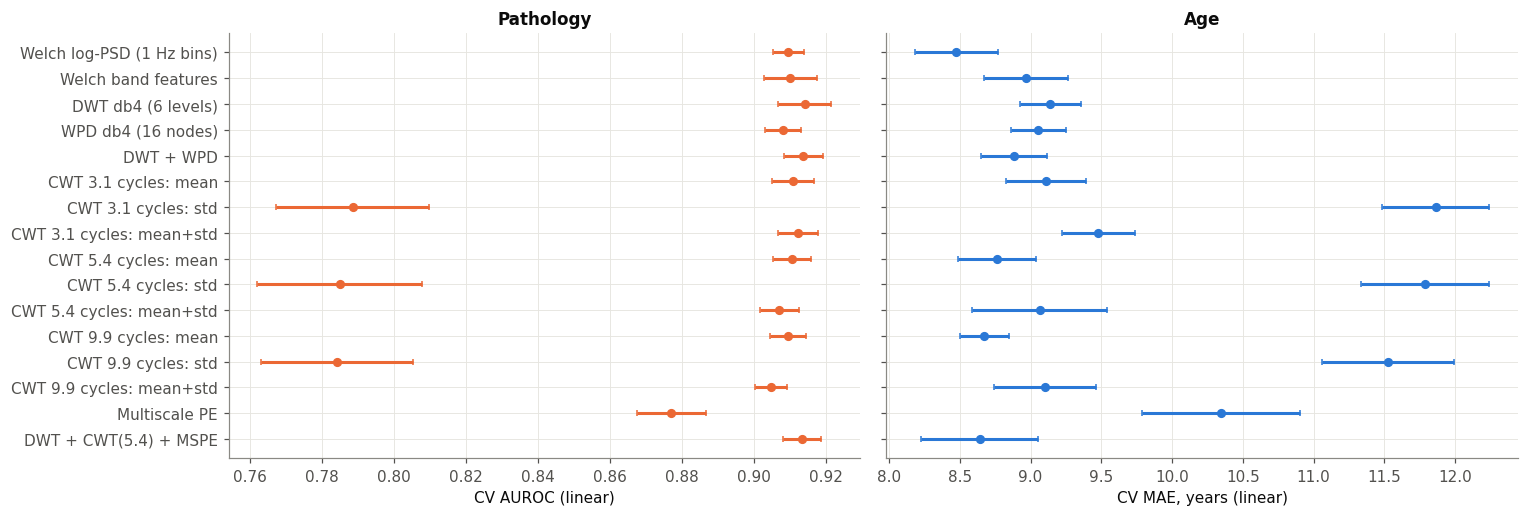

In [22]:
def cwt_part(w, part):
    a = rec(f"cwt_{w}")
    a = a[..., :25] if part == "mean" else (a[..., 25:] if part == "std" else a)
    return nan_to_median(a.reshape(N, -1))

variants = {
    "Welch log-PSD (1 Hz bins)": Xrec("psd_bins"),
    "Welch band features": Xrec("spectral"),
    "DWT db4 (6 levels)": Xrec("dwt_db4_L6"),
    "WPD db4 (16 nodes)": Xrec("wpd_db4_L5"),
    "DWT + WPD": Xrec("dwt_db4_L6", "wpd_db4_L5"),
}
for w, cyc in [("cmor0.5-1.0", 3.1), ("cmor1.5-1.0", 5.4), ("cmor5.0-1.0", 9.9)]:
    variants[f"CWT {cyc} cycles: mean"] = cwt_part(w, "mean")
    variants[f"CWT {cyc} cycles: std"] = cwt_part(w, "std")
    variants[f"CWT {cyc} cycles: mean+std"] = cwt_part(w, "both")
variants["Multiscale PE"] = Xrec("mspe")
variants["DWT + CWT(5.4) + MSPE"] = Xrec("dwt_db4_L6", "cwt_cmor1.5-1.0", "mspe")
rows = []
for name, X in variants.items():
    for task in ("abn", "age"):
        r, _, _ = evaluate(X, task)
        rows.append({"representation": name, "task": task, "n_features": X.shape[1], **r})
ms = pd.DataFrame(rows)
display(ms.pivot_table(index="representation", columns="task", values=["cv_AUROC", "cv_MAE", "test_AUROC", "test_MAE"], sort=False).dropna(axis=1, how="all").round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
names_ = list(variants)
for ax, task, metric, c in [(axes[0], "abn", "cv_AUROC", C_ABN), (axes[1], "age", "cv_MAE", C_NORMAL)]:
    d = ms[ms.task == task].set_index("representation").reindex(names_)
    ax.errorbar(d[metric], range(len(d)), xerr=d[metric + "_sd"], fmt="o", ms=5, capsize=2, color=c)
    ax.set_yticks(range(len(d)), names_ if task == "abn" else [""] * len(d)); ax.invert_yaxis()
    ax.set(xlabel="CV AUROC (linear)" if task == "abn" else "CV MAE, years (linear)", title="Pathology" if task == "abn" else "Age")
plt.tight_layout(); plt.show()

### 6.3 Wavelet scattering networks: does the second order help?
Variants (linear models, reference preparation; gradient boosting on orders 1+2 is in §5):
* **order 1** only (log S1, ≈ constant-Q band energies, 8 filters per octave);
* **order 2** only (log S2/S1, envelope-modulation spectra);
* **orders 1+2**;
* each at two averaging scales: **J = 7** (1.28 s, modulations down to ≈0.3 Hz) and **J = 9** (5.1 s, down to ≈0.07 Hz).

They are compared with the Morlet CWT (mean, and mean+std over time), the closest
non-scattering representation.

n_features         cv_AUROC  cv_MAE  \
task                                       abn     age      abn     age   
representation                                                            
Scattering J=7 (1.28 s): order 1         874.0   874.0    0.909   8.492   
Scattering J=7 (1.28 s): order 2        2451.0  2451.0    0.847  11.128   
Scattering J=7 (1.28 s): orders 1+2     3325.0  3325.0    0.904   9.277   
Scattering J=9 (5.1 s): order 1         1178.0  1178.0    0.908   8.734   
Scattering J=9 (5.1 s): order 2         4503.0  4503.0    0.880  10.179   
Scattering J=9 (5.1 s): orders 1+2      5681.0  5681.0    0.906   9.164   
CWT 5.4 cycles: mean                     475.0   475.0    0.911   8.763   
CWT 5.4 cycles: mean+std                 950.0   950.0    0.907   9.066   
Scattering J=7 1+2 + CWT std            3800.0  3800.0    0.907   9.059   

                                    test_AUROC test_MAE  
task                                       abn      age  
representation                                           
Scattering J=7 (1.28 s): order 1         0.902    7.508  
Scattering J=7 (1.28 s): order 2         0.866   11.640  
Scattering J=7 (1.28 s): orders 1+2      0.907    8.490  
Scattering J=9 (5.1 s): order 1          0.905    7.849  
Scattering J=9 (5.1 s): order 2          0.889   10.443  
Scattering J=9 (5.1 s): orders 1+2       0.911    8.801  
CWT 5.4 cycles: mean                     0.907    7.789  
CWT 5.4 cycles: mean+std                 0.906    8.296  
Scattering J=7 1+2 + CWT std             0.910    8.508

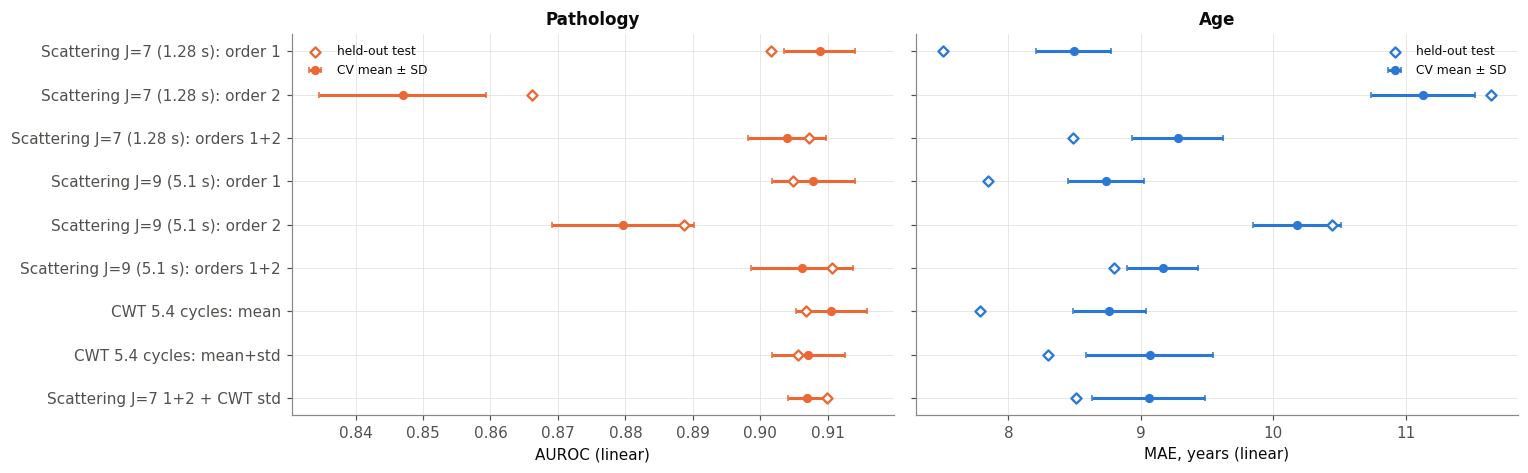

In [23]:
def scat_part(fam, order):
    names_ = NAMES[fam]
    keep = [i for i, n in enumerate(names_) if order == "both" or n.startswith(f"S{order}_")]
    return nan_to_median(rec(fam)[..., keep].reshape(N, -1))

scat_variants = {}
for fam, label in [("scat_J7_Q8", "J=7 (1.28 s)"), ("scat_J9_Q8", "J=9 (5.1 s)")]:
    for order, olab in [("1", "order 1"), ("2", "order 2"), ("both", "orders 1+2")]:
        scat_variants[f"Scattering {label}: {olab}"] = scat_part(fam, order)
scat_variants["CWT 5.4 cycles: mean"] = cwt_part("cmor1.5-1.0", "mean")
scat_variants["CWT 5.4 cycles: mean+std"] = cwt_part("cmor1.5-1.0", "both")
scat_variants["Scattering J=7 1+2 + CWT std"] = np.concatenate([scat_part("scat_J7_Q8", "both"), cwt_part("cmor1.5-1.0", "std")], axis=1)
rows = []
for name, X in scat_variants.items():
    for task in ("abn", "age"):
        r, _, _ = evaluate(X, task)
        rows.append({"representation": name, "task": task, "n_features": X.shape[1], **r})
scat = pd.DataFrame(rows)
display(scat.pivot_table(index="representation", columns="task", values=["n_features", "cv_AUROC", "cv_MAE", "test_AUROC", "test_MAE"], sort=False).dropna(axis=1, how="all").round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
names_ = list(scat_variants)
for ax, task, metric in [(axes[0], "abn", "cv_AUROC"), (axes[1], "age", "cv_MAE")]:
    c = C_ABN if task == "abn" else C_NORMAL
    d = scat[scat.task == task].set_index("representation").reindex(names_)
    ax.errorbar(d[metric], np.arange(len(d)), xerr=d[metric + "_sd"], fmt="o", ms=5, capsize=2, color=c, label="CV mean ± SD")
    ax.scatter(d["test_" + metric[3:]], np.arange(len(d)), marker="D", s=22, facecolor="white", edgecolor=c, lw=1.5, zorder=3, label="held-out test")
    ax.set_yticks(range(len(names_)), names_)
    ax.set(xlabel="AUROC (linear)" if task == "abn" else "MAE, years (linear)", title="Pathology" if task == "abn" else "Age")
    ax.legend(fontsize=8)
axes[0].invert_yaxis()
plt.tight_layout(); plt.show()

Where is the second-order information? Each cell below is one (rhythm λ1, modulation λ2)
pair of the J = 9 network. It shows the channel-averaged univariate AUROC for pathology and
the Spearman ρ with age (normal recordings), computed on the development pool.

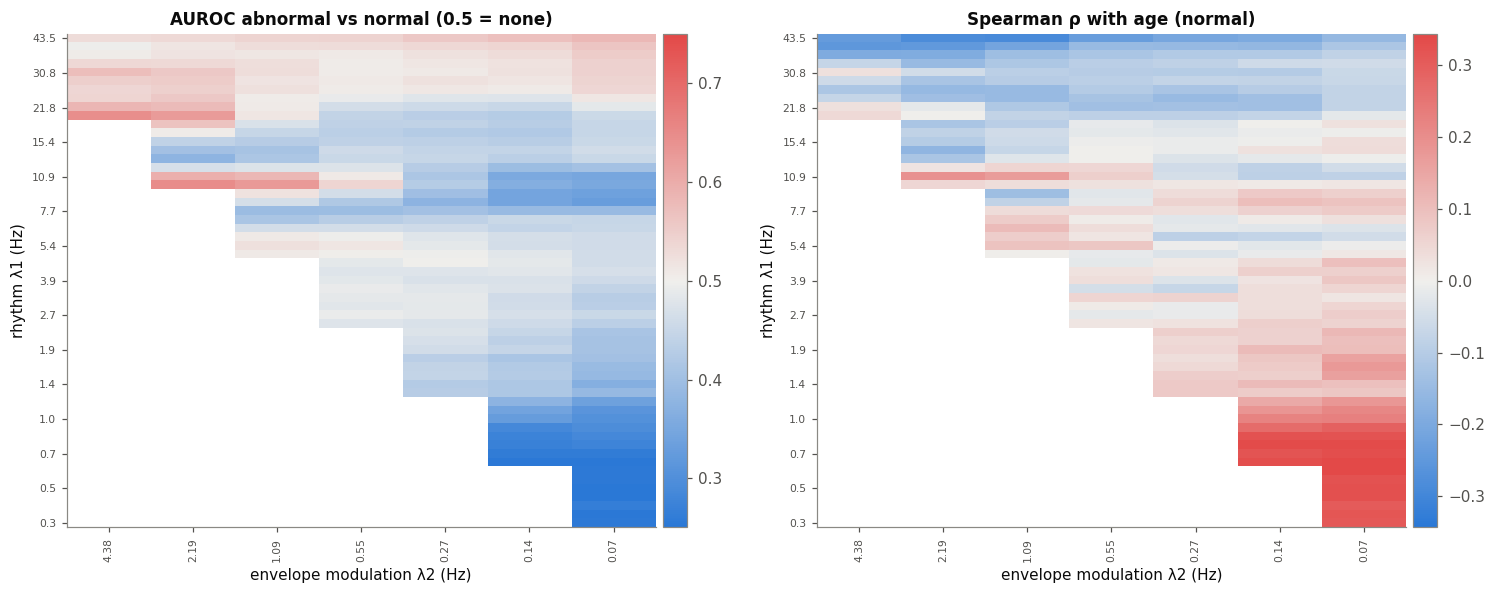

strongest second-order coefficients for pathology: [('0.4 Hz x 0.07 Hz', 0.251), ('0.5 Hz x 0.07 Hz', 0.252), ('0.6 Hz x 0.07 Hz', 0.254), ('0.6 Hz x 0.14 Hz', 0.254), ('0.3 Hz x 0.07 Hz', 0.254)]
strongest second-order coefficients for age: [('0.6 Hz x 0.07 Hz', 0.343), ('0.6 Hz x 0.07 Hz', 0.341), ('0.7 Hz x 0.14 Hz', 0.338), ('0.7 Hz x 0.07 Hz', 0.335), ('0.7 Hz x 0.07 Hz', 0.331)]


In [24]:
fam = "scat_J9_Q8"
names_ = NAMES[fam]
i2 = [i for i, n in enumerate(names_) if n.startswith("S2_")]
f1 = np.array([float(names_[i].split("_")[1][:-2]) for i in i2])
f2 = np.array([float(names_[i].split("mod")[1][:-2]) for i in i2])
vals = rec(fam)[:, :, i2].mean(axis=1)  # channel-averaged log S2/S1
auc2 = np.array([roc_auc_score(Y["abn"][DEV["abn"]], vals[DEV["abn"], j]) for j in range(len(i2))])
rho2 = np.array([stats.spearmanr(vals[DEV["age"], j], age[DEV["age"]])[0] for j in range(len(i2))])
u1, u2 = np.unique(f1)[::-1], np.unique(f2)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, v, title, centre in [(axes[0], auc2, "AUROC abnormal vs normal (0.5 = none)", 0.5),
                             (axes[1], rho2, "Spearman ρ with age (normal)", 0.0)]:
    M = np.full((len(u1), len(u2)), np.nan)
    for a, b, val in zip(f1, f2, v):
        M[np.searchsorted(-u1, -a), np.searchsorted(-u2, -b)] = val
    lim = np.nanmax(np.abs(M - centre))
    im = ax.imshow(M, cmap=DIV, vmin=centre - lim, vmax=centre + lim, aspect="auto")
    ax.set_yticks(range(0, len(u1), 4), [f"{x:.1f}" for x in u1[::4]], fontsize=7)
    ax.set_xticks(range(len(u2)), [f"{x:.2f}" for x in u2], fontsize=7, rotation=90)
    ax.set(ylabel="rhythm λ1 (Hz)", xlabel="envelope modulation λ2 (Hz)", title=title); ax.grid(False)
    plt.colorbar(im, ax=ax, pad=0.01)
plt.tight_layout(); plt.show()
best = np.argsort(-np.abs(auc2 - 0.5))[:5]
print("strongest second-order coefficients for pathology:",
      [(f"{f1[j]:.1f} Hz x {f2[j]:.2f} Hz", round(auc2[j], 3)) for j in best])
best = np.argsort(-np.abs(rho2))[:5]
print("strongest second-order coefficients for age:",
      [(f"{f1[j]:.1f} Hz x {f2[j]:.2f} Hz", round(rho2[j], 3)) for j in best])

## 7. Combined model, family ablation, and the brain-age gap

### 7.1 Leave-one-family-out
Starting from the full feature set (linear models), each family is dropped in turn. A large
drop means the family carries information that the others do not.

In [25]:
flat_fams = list(ALL_FLAT)
full = {t: bench[(bench.family == "All families combined") & (bench.model == "linear") & (bench.task == t)].iloc[0] for t in ("abn", "age")}
rows = []
for drop in flat_fams + ["riemann"]:
    keep = [f for f in flat_fams if f != drop]
    Xf = Xrec(*keep)
    if drop == "riemann":
        X, pre = Xf, None
    else:
        X, pre = np.concatenate([Xf, X_FB], axis=1), FBTangentSpace(n_passthrough=Xf.shape[1])
    for task in ("abn", "age"):
        r, _, _ = evaluate(X, task, pre=pre, run_test=False)
        rows.append({"dropped": drop, "task": task, **r})
abl = pd.DataFrame(rows)
abl["delta"] = np.where(abl.task == "abn", abl.cv_AUROC - full["abn"].cv_AUROC, abl.cv_MAE - full["age"].cv_MAE)
display(abl.pivot(index="dropped", columns="task", values="delta").rename(
    columns={"abn": "Δ AUROC (neg = family helps)", "age": "Δ MAE (pos = family helps)"}).round(4))

task,Δ AUROC (neg = family helps),Δ MAE (pos = family helps)
dropped,,
cwt_cmor1.5-1.0,-0.0015,0.1567
dwt_db4_L6,-0.0004,0.0191
mspe,0.0000,0.0678
psd_bins,0.0002,0.0365
riemann,-0.0072,0.3817
scat_J7_Q8,0.0011,-0.1353
spectral,0.0002,0.0173
time,-0.0001,0.0180
wpd_db4_L5,0.0001,0.0029


### 7.2 Brain-age gap of abnormal EEGs
The best age model (by CV MAE) is trained on normal recordings and then applied to the held-out
test set: normals *and* abnormals. Brain-age estimates regress towards the mean, so the gap
(predicted − chronological age) is **bias-corrected** with a linear fit of the out-of-fold gap
on age in the training pool (Smith et al. 2019 / de Lange & Cole 2020).

best age model: All families combined / linear (CV MAE 8.04, test MAE 7.20)


bias fit on training OOF: gap = -0.45*age + 19.6
test normal  : MAE 7.20 y, corrected gap mean -0.66 y
test abnormal: MAE 13.20 y, corrected gap mean -2.15 y
AUROC of the corrected brain-age gap for abnormal vs normal: 0.457 (Mann-Whitney p=0.22)


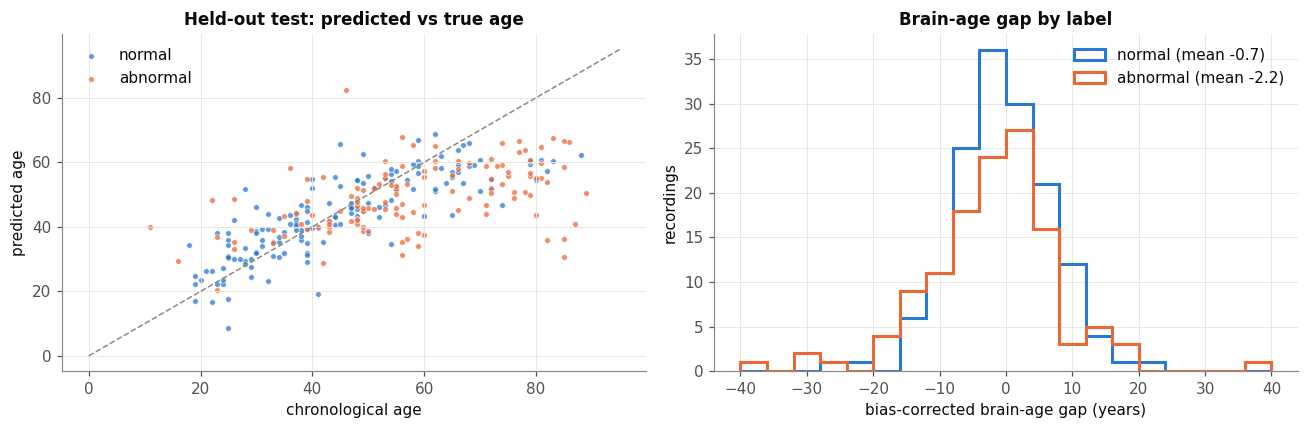

In [26]:
age_bench = bench[(bench.task == "age") & ~bench.family.str.startswith("Baseline")]
best_row = age_bench.sort_values("cv_MAE").iloc[0]
print(f"best age model: {best_row.family} / {best_row.model} (CV MAE {best_row.cv_MAE:.2f}, test MAE {best_row.test_MAE:.2f})")
fams = FAMILIES.get(best_row.family, "all")
if fams == "riemann":
    X, pre = X_FB, FBTangentSpace()
elif fams == "all":
    Xf = Xrec(*ALL_FLAT); X, pre = np.concatenate([Xf, X_FB], axis=1), FBTangentSpace(n_passthrough=Xf.shape[1])
else:
    X, pre = Xrec(*fams), None
oof = PRED[(best_row.family, best_row.model, "age")][0]
idx = DEV["age"]
slope, icpt = np.polyfit(age[idx], oof - age[idx], 1)  # gap = slope*age + icpt in training (OOF)
model = make_model("age", best_row.model)
model = (make_pipeline(clone(pre), model) if pre is not None else model)
with threadpool_limits(N_JOBS):
    model.fit(X[idx], age[idx])
te = np.where(test & age_ok)[0]
pred = model.predict(X[te])
gap = pred - age[te] - (slope * age[te] + icpt)
is_abn = meta.abnormal.to_numpy()[te] == 1
print(f"bias fit on training OOF: gap = {slope:.2f}*age + {icpt:.1f}")
print(f"test normal  : MAE {np.abs(pred[~is_abn] - age[te][~is_abn]).mean():.2f} y, corrected gap mean {gap[~is_abn].mean():+.2f} y")
print(f"test abnormal: MAE {np.abs(pred[is_abn] - age[te][is_abn]).mean():.2f} y, corrected gap mean {gap[is_abn].mean():+.2f} y")
u = stats.mannwhitneyu(gap[is_abn], gap[~is_abn])
print(f"AUROC of the corrected brain-age gap for abnormal vs normal: {u.statistic / (is_abn.sum() * (~is_abn).sum()):.3f} (Mann-Whitney p={u.pvalue:.2g})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for m, lab, c in [(~is_abn, "normal", C_NORMAL), (is_abn, "abnormal", C_ABN)]:
    axes[0].scatter(age[te][m], pred[m], s=14, color=c, alpha=0.75, label=lab, edgecolor="white", linewidth=0.5)
    axes[1].hist(gap[m], bins=np.arange(-40, 41, 4), histtype="step", lw=2, color=c, label=f"{lab} (mean {gap[m].mean():+.1f})")
axes[0].plot([0, 95], [0, 95], color="#8a8984", lw=1, ls="--")
axes[0].set(xlabel="chronological age", ylabel="predicted age", title="Held-out test: predicted vs true age"); axes[0].legend()
axes[1].set(xlabel="bias-corrected brain-age gap (years)", ylabel="recordings", title="Brain-age gap by label"); axes[1].legend()
plt.tight_layout(); plt.show()

## 8. Conclusions and recommendations

### What the data say

**Data preparation (§3)**
1. **Re-reference first.** Moving from the stored 23-channel montage to the 19 scalp channels with a common average reference was the largest single gain: pathology AUROC 0.893 → 0.914, age MAE 9.89 → 9.00 years (core features).
2. **Low-pass at 45 Hz, or notch at 60 Hz.** `make_TUAB.py` notches **50 Hz**, but TUH was recorded in the US. The 60 Hz line survives, is strong in 20% of recordings, and its level differs by label (AUROC 0.61). Band-limiting to 1–45 Hz improved time features by +0.045 AUROC and age by 0.07–0.55 years depending on the family. The same 60 Hz content is in LaBraM's own fine-tuning input (0.1–75 Hz).
3. **Cropping and rejection have small effects on recording-level features.** The first minute has about 3× more rejected windows (9.7% vs 3.6%), but skipping it and rejecting ±800 µV windows changed AUROC by ≤ 0.01 and age MAE by ≤ 0.25 y. Median aggregation was no better than the mean, and slightly worse for age, unlike Gemein 2020.
4. **Length.** 10 s of EEG already gives AUROC 0.89. Pathology saturates after about 2–3 min. Age keeps improving up to the 5 min used here (10.3 → 8.8 y), so use as much clean EEG as possible for brain age.

**Feature families (§4–5)**
5. The best single **pathology** features are posterior and temporal **θ/α and (δ+θ)/(α+β) ratios** (AUROC up to 0.85), i.e. background slowing. The best single **age** features are frontal-central δ/low-θ power, which falls with age. Peak alpha frequency (≈10 Hz in normals, slowing after 50; ≈8 Hz in abnormal EEG) and the **1/f exponent** (flattening with age in normals; steeper in abnormal EEG) behave as the literature predicts.
6. **Filterbank-Riemann is the best single family for both targets** (0.922 AUROC; 8.22 y, matching Engemann et al.'s 8.25 y on TUAB). In the leave-one-family-out analysis it is also the family carrying the most unique information (−0.007 AUROC, +0.38 y when removed). Spatial covariance (coupling) is information that per-channel features lack.
7. Every spectral-type representation (Welch bands or bins, DWT, WPD, CWT, scattering S1) lands at **0.90–0.92 AUROC**. This is consistent with Gemein's "plateau" and with label noise limiting TUAB. Combining everything reaches 0.925 CV / 0.929 test AUROC (balanced accuracy 0.85) and 8.04 CV / 7.20 test MAE.
8. **Linear models beat gradient boosting for age**, by 0.8–1.5 y on every family except the time-domain one. For pathology they are on par, with boosting slightly ahead on the held-out set.

**Multi-scale methods (§6)**
9. **Mother wavelet:** irrelevant for pathology (spread 0.009 AUROC ≈ 1 fold SD). For age, short or poorly selective wavelets (Haar 9.49 y, bior3.5 9.70 y) are worst, and longer orthogonal ones (db8 8.96, sym4/sym9/coif3 ≈ 9.04) are best. The sine-sweep figure shows why: Haar leaks energy across levels. On the 149-recording test set the ranking is noisy (8.2–8.5 y), so treat differences under 0.3 y as ties. **Depth:** 4 levels is too shallow at 200 Hz (A4 = 0–6 Hz merges δ and θ); 5–7 are equivalent.
10. **CWT:** the time-averaged log scalogram is what carries the signal, and more cycles (finer frequency resolution) are better for age (9.9 cycles: 8.67 y vs 3.1 cycles: 9.11 y). The within-window variability (std over time) is informative on its own (AUROC 0.79) but **redundant** with the mean, and adding it slightly hurts.
11. **Wavelet scattering:** order-1 coefficients (8 wavelets/octave) are the best wavelet representation for age (8.49 y CV, 7.51 y test), on par with 1 Hz Welch bins. Second-order (envelope-modulation) coefficients alone reach 0.85–0.88 AUROC but add nothing on top of order 1 at recording level, and removing them from the combined model *improves* age MAE by 0.14 y. Their largest effects are **slow-delta (0.3–1 Hz) envelope modulations at 0.07–0.14 Hz**, which are lower (less bursty) in abnormal EEG and higher with age. Those bands sit at the edge of the 1 Hz high-pass, so they may also reflect slow drifts or eye movements. **Alpha modulated at ~2 Hz** is higher in abnormal EEG. A longer averaging scale (J = 9) helps order 2 (0.880 vs 0.847 AUROC), as expected for slow modulations.
12. **Multiscale permutation entropy** shows the expected developmental shift (children have lower fine-scale entropy), but it is the weakest family.

**Brain-age gap (§7)**
13. A ridge model trained on normal recordings predicts normal test ages with MAE 7.2 y, but abnormal ages with MAE 13.2 y. Its bias-corrected gap does **not** separate abnormal from normal (AUROC 0.46, p = 0.22), and if anything abnormal recordings look *younger*. Pathological slowing (more δ/θ, steeper 1/f) resembles the developmental end of the age axis. So a brain-age gap built on these features is not a pathology marker on TUAB. It would need features that are age-specific but pathology-invariant, or a different reference population.

### Recommendations
* **Pipeline:** 19 × 10-20 channels → CAR → 1–45 Hz (or 0.1–45 Hz + 60 Hz notch) → 200 Hz → skip 1 min → reject > 800 µV / flat windows → features per 10 s window → mean/median per recording → log power → standardise. Train age models on normals. Use subject-grouped CV.
* **Pathology:** a Welch band-ratio set (≈ 300 features) already gets 0.91 AUROC. Add filterbank-Riemann for the last 1–2 points.
* **Age:** filterbank-Riemann + a fine-resolution spectrum (1 Hz Welch bins or scattering S1), with a ridge regression, on ≥ 5 min of clean EEG.
* **If you use wavelets:** DWT with db8 / sym4–9 / coif3 at 5–7 levels (log + relative energy + wavelet entropy). CWT with complex Morlet at 7–10 cycles on log-spaced frequencies, summarised by mean log power. Wavelet scattering: order 1 with Q = 8 as a compact constant-Q spectrum. Keep order 2 for **window-level / event** tasks (seizures, spikes, intermittent slowing), where envelope dynamics matter more than in recording-level averages.
* **For the LaBraM pipeline:** revisit the 50 Hz notch in `make_TUAB.py` for TUH (use 60 Hz, or low-pass ≤ 45 Hz), and consider CAR. The ablation suggests both matter more than the choice of representation. The numbers here (0.925 AUROC / 8.0 y at recording level) are the classical-ML bar a fine-tuned LaBraM should clear, once its window predictions are aggregated per recording.